# Evaluación de la deformación superficial asociada a movimientos en masa mediante análisis InSAR y datos GNSS en la cuenca media y baja del río Suárez, Colombia

## Notebook 2 de 3. Componente GNSS: series de posición diaria y velocidades

**Autores:** Mariana Paredes Galindo · Sair Granada Garzón  
**Director:** José Pedro Mora Ortiz, Geólogo, MSc. en Sistemas de Información Geográfica y MSc. en Geofísica  
**Codirector:** José Luis Gómez Díaz, Ing. Catastral y Geodesta, MSc. en Ciencias de la Geoinformación y Observación de la Tierra  

Universidad Industrial de Santander · Facultad de Ingenierías Fisicoquímicas · Escuela de Geología  
Bucaramanga, 2026

Este notebook procesa solo las series GNSS. Parte de las posiciones diarias de 12 estaciones de operación continua del Nevada Geodetic Laboratory (NGL), solución IGS20, desde el 1 de enero de 2016, y entrega para cada estación y componente (este, norte y vertical) la velocidad con su incertidumbre. El procedimiento replica en Python los pasos del análisis de series temporales con SARI (Santamaría-Gómez, 2019): modelo de trayectoria, valores atípicos, saltos por equipo y sismos, análisis de ruido y estimador MIDAS.

## 1. Librerías

Importa las librerías que usa el análisis. El aspecto de las figuras y las tablas se define en la celda de diseño que sigue, igual en los tres notebooks.

| Librería | Uso | Referencia |
|---|---|---|
| Biblioteca estándar (`pathlib`, `re`, `urllib`, `html`) | Rutas, texto, descargas y tablas | Python Software Foundation (2024) |
| `numpy` | Arreglos, matrices de diseño y estadísticas | Harris et al. (2020) |
| `pandas` | Tablas de series, saltos, sismos y resultados | McKinney (2010) |
| `scipy` | Álgebra lineal, descomposición de Cholesky y optimización | Virtanen et al. (2020) |
| `matplotlib` | Figuras | Hunter (2007) |

In [1]:
# Biblioteca estandar
import html
import re
import textwrap
import urllib.request
from pathlib import Path

# Calculo numerico y tablas
import numpy as np
import pandas as pd
import scipy
from scipy import linalg, optimize

# Datos vectoriales (opcional: solo para dibujar la cuenca)
try:
    import geopandas as gpd
except ImportError:
    gpd = None

# Graficas y salidas del cuaderno
import matplotlib
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

FIG_ANCHO_ESTACION = 8.6   # las figuras de estación son más anchas para la lista de sismos
PIE_ANCHO = 175            # caracteres por línea en el pie de las figuras de estación


print("ok: librerías cargadas")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

ok: librerías cargadas
numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1


### Diseño de figuras y tablas

Esta celda es la misma en los tres notebooks, para que todo el trabajo se vea igual. Fija la fuente (Times New Roman o la serif más parecida), la paleta (azul para lo que se aleja o desciende, rojo para lo que se acerca o asciende, gris para los datos), el ancho de 6,5 pulgadas, las marcas de los ejes hacia adentro y las letras de panel en recuadros blancos. Los títulos de figura y de tabla llevan solo el número y el nombre; lo que cada una muestra se explica en el texto de su celda.

In [2]:
# Diseño común de los tres notebooks: fuente, paleta, estilo de los ejes, títulos de figura y tablas
import html

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib import font_manager
from matplotlib.lines import Line2D

# Fuente: Times New Roman o la serif más parecida que esté instalada
FUENTES = ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"]
instaladas = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next(f for f in FUENTES if f in instaladas or f == "DejaVu Serif")

# Medidas y colores
FIG_ANCHO = 6.5            # pulgadas, ancho útil de la página
ESCALA_KM = 20             # longitud de la escala gráfica de los mapas, km
FONDO = "#ececec"
COLOR_AZUL, COLOR_ROJO, COLOR_DATOS, COLOR_NARANJA = "#2166ac", "#b2182b", "#9a9a9a", "#e08214"
PALETA_VELOCIDAD, PALETA_INCERTIDUMBRE = "RdBu_r", "magma_r"
# Color de cada geometría (descendente en azul, ascendente en rojo) y un tono claro para un segundo stack de la misma geometría
COLORES_STACK = {"DESCENDING": [COLOR_AZUL, "#5aa0d0"], "ASCENDING": [COLOR_ROJO, "#e06a5a"]}
# Series temporales: un color por geometría (el segundo stack de la misma geometría, más claro) y GNSS en negro
COLORES_STACK = {"DESCENDING": [COLOR_AZUL, "#5aa0d0"], "ASCENDING": [COLOR_ROJO, "#e06a5a"]}
COLOR_GNSS = "black"

plt.rcParams.update({
    "font.family": "serif", "font.serif": [FUENTE], "mathtext.fontset": "stix", "font.size": 8,
    "axes.linewidth": 0.8, "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.titlesize": 9,
    "axes.axisbelow": True, "grid.color": "0.88", "grid.linewidth": 0.5, "lines.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "legend.fontsize": 7, "legend.framealpha": 0.9, "legend.edgecolor": "0.8",
    "figure.dpi": 120,
})
TIPO_HTML = "font-family:'Times New Roman',Times,serif;font-size:13px"


# Número con coma decimal
def coma(valor, decimales=1):
    return f"{valor:.{decimales}f}".replace(".", ",")


# Grados decimales a texto en grados y minutos con hemisferio
def gms(valor, positivo, negativo):
    total = round(abs(valor) * 60)
    return f"{total // 60}°{total % 60:02d}'{positivo if valor >= 0 else negativo}"


# Letra del panel en un recuadro blanco
def letra_panel(eje, letra, x=0.03, y=0.965):
    eje.text(x, y, letra, transform=eje.transAxes, ha="left", va="top", fontsize=9, fontweight="bold",
             bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="black", lw=0.6), zorder=6)


# Marcas hacia adentro en los cuatro bordes y borde de 0,8 pt
def estilo_eje(eje):
    eje.tick_params(labelsize=7, direction="in", length=3, top=True, right=True)
    for borde in eje.spines.values():
        borde.set_linewidth(0.8)


# Marcas de longitud en el borde inferior y de latitud en el izquierdo, en grados y minutos
def coordenadas_geograficas(eje, epsg, paso_x, paso_y):
    from pyproj import Transformer
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    a_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    a_map = Transformer.from_crs(4326, epsg, always_xy=True)
    lon_min, lat_min = a_geo.transform(x0, y0)
    lon_max, lat_max = a_geo.transform(x1, y1)
    _, lat_borde = a_geo.transform((x0 + x1) / 2, y0)
    lon_borde, _ = a_geo.transform(x0, (y0 + y1) / 2)
    lons = np.arange(np.ceil(lon_min / paso_x) * paso_x, lon_max, paso_x)
    lats = np.arange(np.ceil(lat_min / paso_y) * paso_y, lat_max, paso_y)
    xs = [(a_map.transform(lon, lat_borde)[0], lon) for lon in lons]
    ys = [(a_map.transform(lon_borde, lat)[1], lat) for lat in lats]
    xs = [(x, v) for x, v in xs if x0 + 0.04 * (x1 - x0) < x < x1 - 0.04 * (x1 - x0)]
    ys = [(y, v) for y, v in ys if y0 + 0.03 * (y1 - y0) < y < y1 - 0.03 * (y1 - y0)]
    eje.set_xticks([x for x, _ in xs])
    eje.set_xticklabels([gms(v, "E", "W") for _, v in xs])
    eje.set_yticks([y for y, _ in ys])
    eje.set_yticklabels([gms(v, "N", "S") for _, v in ys], rotation=90, va="center")


# Inserta NaN donde hay huecos mayores que "dias" para que la línea no cruce los vacíos
def cortar_huecos(fechas, valores, dias=60):
    fechas = pd.DatetimeIndex(fechas)
    corte = np.where(np.diff(fechas.asi8) / 86.4e12 > dias)[0] + 1
    return np.insert(fechas.to_numpy(), corte, np.datetime64("NaT")), np.insert(np.asarray(valores, dtype=float), corte, np.nan)


# Serie temporal en el estilo común: puntos, mediana móvil de "ventana" fechas y tendencia lineal discontinua.
# Devuelve la pendiente en mm/año (la ajustada, o la dada en "pendiente")
def trazar_serie(eje, fechas, serie, color, ventana=5, hueco=60, tamano=2.6, color_puntos=None, pendiente=None):
    fechas, serie = pd.DatetimeIndex(fechas), np.asarray(serie, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, serie, 1)
    else:
        intercepto = np.median(serie - pendiente * anios)
    eje.plot(fechas, serie, "o", ms=tamano, color=color_puntos or color, alpha=0.55, mew=0, zorder=2)
    suave = pd.Series(serie).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(*cortar_huecos(fechas, suave, hueco), "-", lw=1.2, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.0, color=color, zorder=5)
    return float(pendiente)


# Eje de una serie temporal: años en x, rejilla horizontal, línea en cero y un margen de 30 días a cada lado
def estilo_serie(eje, inicio, fin):
    eje.set_xlim(inicio - pd.Timedelta(days=30), fin + pd.Timedelta(days=30))
    eje.xaxis.set_major_locator(mdates.YearLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eje.axhline(0, color="0.6", lw=0.5, zorder=0)
    eje.grid(axis="y")
    estilo_eje(eje)


# Leyenda de una serie temporal: con recuadro claro y sin negrita
def leyenda_serie(eje, manijas):
    eje.legend(handles=manijas, loc="best", frameon=True)


# Norte en la esquina superior derecha y escala gráfica en la inferior izquierda, sobre recuadros blancos (mapa en metros)
def norte_y_escala(eje, escala_km=ESCALA_KM):
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    ancho, alto = x1 - x0, y1 - y0
    bx, by, largo = x0 + 0.08 * ancho, y0 + 0.04 * alto, escala_km * 1000
    eje.add_patch(plt.Rectangle((bx - 0.05 * ancho, by - 0.017 * alto), largo + 0.24 * ancho, 0.06 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    for i in range(2):
        eje.add_patch(plt.Rectangle((bx + i * largo / 2, by), largo / 2, 0.009 * alto,
                                    facecolor="black" if i == 0 else "white", edgecolor="black", lw=0.4, zorder=5))
    for v, x in ((0, bx), (escala_km // 2, bx + largo / 2), (escala_km, bx + largo)):
        eje.text(x, by + 0.014 * alto, f"{v}", ha="center", va="bottom", fontsize=5.5, zorder=5)
    eje.text(bx + largo + 0.04 * ancho, by + 0.005 * alto, "km", va="center", fontsize=5.5, zorder=5)
    nx, ny = x1 - 0.1 * ancho, y1 - 0.12 * alto
    eje.add_patch(plt.Rectangle((nx - 0.055 * ancho, ny - 0.01 * alto), 0.11 * ancho, 0.1 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    eje.annotate("", xy=(nx, ny + 0.055 * alto), xytext=(nx, ny + 0.002 * alto),
                 arrowprops=dict(facecolor="black", edgecolor="black", width=1.5, headwidth=4.5, headlength=4), zorder=5)
    eje.text(nx, ny + 0.058 * alto, "N", ha="center", va="bottom", fontsize=6.5, fontweight="bold", zorder=5)


# Barra de colores horizontal con rótulo; con límite, marcas cada 10 unidades
def barra_colores(fig, imagen, ejes, rotulo, limite=None, encoger=0.6):
    marcas = range(-limite, limite + 1, 10) if limite else None
    barra = fig.colorbar(imagen, ax=ejes, orientation="horizontal", shrink=encoger, pad=0.02, aspect=40, ticks=marcas)
    barra.set_label(rotulo, fontsize=8)
    barra.ax.tick_params(labelsize=7)
    return barra


# Título de una figura, que se muestra encima de ella: "Figura N" en negrita (si se da el número) y el título en cursiva
def titulo_figura(titulo, numero=None):
    cabeza = f'<div style="font-weight:bold">Figura {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 2px">{cabeza}'
                 f'<div style="font-style:italic">{html.escape(titulo)}</div></div>'))


# Inserta NaN donde hay un hueco de más de max_dias días, para que la línea no lo cruce
def romper_huecos(fechas, valores, max_dias=30):
    f, v = [fechas[0]], [valores[0]]
    for k in range(1, len(fechas)):
        if (fechas[k] - fechas[k - 1]).days > max_dias:
            f.append(fechas[k - 1] + pd.Timedelta(days=1))
            v.append(np.nan)
        f.append(fechas[k])
        v.append(valores[k])
    return pd.DatetimeIndex(f), np.array(v, dtype=float)


# Serie de desplazamiento: puntos, mediana móvil y tendencia lineal (discontinua). Devuelve el elemento de la leyenda
def dibujar_serie(eje, fechas, valores, color, etiqueta, ventana=5, color_puntos=None, pendiente=None, tam=2.8, max_hueco=30):
    fechas, valores = pd.DatetimeIndex(fechas), np.asarray(valores, dtype=float)
    anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
    if pendiente is None:
        pendiente, intercepto = np.polyfit(anios, valores, 1)
    else:
        intercepto = np.median(valores - pendiente * anios)
    color_puntos = color_puntos or color
    suave = pd.Series(valores).rolling(ventana, center=True, min_periods=1).median().to_numpy()
    eje.plot(fechas, valores, "o", ms=tam, color=color_puntos, alpha=0.55, mew=0, zorder=3)
    eje.plot(*romper_huecos(fechas, suave, max_hueco), "-", lw=1.3, color=color, zorder=4)
    eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.0, color=color, zorder=5)
    return Line2D([], [], color=color, lw=1.3, marker="o", ms=3, mfc=color_puntos, mec="none", label=etiqueta)


# Formato común de una serie temporal: línea en cero, cuadrícula horizontal, fechas legibles y rótulo del eje y
def formato_serie(eje, rotulo="Desplazamiento en la línea de vista (mm)"):
    inicio, fin = (mdates.num2date(v) for v in eje.get_xlim())
    anios = (fin - inicio).days / 365.25
    if anios <= 1.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 4, 7, 10)), "%Y-%m"
    elif anios <= 3.5:
        localizador, formato = mdates.MonthLocator(bymonth=(1, 7)), "%Y-%m"
    else:
        localizador, formato = mdates.YearLocator(), "%Y"
    eje.xaxis.set_major_locator(localizador)
    eje.xaxis.set_major_formatter(mdates.DateFormatter(formato))
    eje.axhline(0, color="0.6", lw=0.5, zorder=0)
    eje.grid(axis="y")
    eje.set_ylabel(rotulo)
    estilo_eje(eje)


# Texto de una celda de tabla: coma decimal, decimales parejos por columna y guion para los vacíos
def texto_celda(valor, decimales):
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "-"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:,.{decimales}f}".replace(",", " ").replace(".", ",")
    if isinstance(valor, (int, np.integer)):
        return f"{valor:,}".replace(",", " ") if abs(valor) >= 10000 else str(valor)
    return html.escape(str(valor))


# Tabla en formato APA 7: número (opcional), título en cursiva y solo líneas horizontales.
# Con agrupar="Columna", los valores repetidos de esa primera columna salen una sola vez y los grupos se separan con una línea fina
def tabla_apa(tabla, titulo, numero=None, agrupar=None):
    if tabla is None or len(tabla) == 0:
        return
    linea, fina = "1.5px solid currentColor", "1px solid #bbbbbb"
    decimales = {}
    for col in tabla.columns:
        valores = [v for v in tabla[col] if isinstance(v, (float, np.floating)) and np.isfinite(v)]
        partes = [f"{round(float(v), 2)}".split(".")[1] for v in valores]
        decimales[col] = max([1] + [len(p.rstrip("0")) for p in partes])
    cabeza = "".join(f'<th style="border-top:{linea};border-bottom:1px solid currentColor;padding:3px 10px;'
                     f'font-weight:normal;text-align:center">{html.escape(str(col))}</th>' for col in tabla.columns)
    inicios, tamanos = {}, {}
    if agrupar is not None:
        grupo = list(tabla[agrupar])
        for k, v in enumerate(grupo):
            if k == 0 or v != grupo[k - 1]:
                inicios[k], actual = v, k
                tamanos[k] = 0
            tamanos[actual] += 1
    filas, ultimo = [], len(tabla) - 1
    for k, (_, fila) in enumerate(tabla.iterrows()):
        borde = f"border-bottom:{linea};" if k == ultimo else ""
        if agrupar is not None and k in inicios and k > 0:
            borde += f"border-top:{fina};"
        celdas = []
        for col in tabla.columns:
            valor = fila[col]
            if col == agrupar:
                if k in inicios:
                    cierre = f"border-bottom:{linea};" if k + tamanos[k] - 1 == ultimo else ""
                    sup = f"border-top:{fina};" if k > 0 else ""
                    celdas.append(f'<td rowspan="{tamanos[k]}" style="{cierre}{sup}padding:2px 10px;text-align:left;'
                                  f'vertical-align:top;font-weight:bold">{texto_celda(valor, 0)}</td>')
                continue
            alinear = "right" if isinstance(valor, (int, float, np.integer, np.floating)) else "left"
            celdas.append(f'<td style="{borde}padding:2px 10px;text-align:{alinear}">{texto_celda(valor, decimales[col])}</td>')
        filas.append("<tr>" + "".join(celdas) + "</tr>")
    encabezado = f'<div style="font-weight:bold">Tabla {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 14px">{encabezado}'
                 f'<div style="font-style:italic;margin-bottom:4px">{html.escape(titulo)}</div>'
                 f'<table style="border-collapse:collapse;{TIPO_HTML}"><thead><tr>{cabeza}</tr></thead>'
                 f'<tbody>{"".join(filas)}</tbody></table></div>'))


print(f"ok: diseño cargado | fuente de las figuras: {FUENTE}")

ok: diseño cargado | fuente de las figuras: Liberation Serif


## 2. Rutas

Define la carpeta del proyecto, la de los datos GNSS y las de resultados. Las series, el archivo de saltos y los catálogos de sismos de cada estación se guardan juntos en `01_datos/gnss/`:

    <proyecto>/
    ├── 01_datos/gnss/   AAAA.tenv3, steps.txt, sismos_usgs_AAAA.csv
    └── 03_resultados/   gnss/ (figuras y tablas)

In [3]:
BASE_DIR = Path.home() / "Tesis_InSAR_Rio_Suarez"
GNSS_DIR = BASE_DIR / "01_datos" / "gnss"
RESULTADOS_DIR = BASE_DIR / "03_resultados" / "gnss"

if not BASE_DIR.exists():
    raise FileNotFoundError(f"no existe {BASE_DIR}")
for carpeta in (GNSS_DIR, RESULTADOS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)
print(f"datos GNSS: {len(list(GNSS_DIR.glob('*.tenv3')))} series en {GNSS_DIR}")
print(f"ok: resultados en {RESULTADOS_DIR}")

datos GNSS: 12 series en /home/jovyan/Tesis_InSAR_Rio_Suarez/01_datos/gnss
ok: resultados en /home/jovyan/Tesis_InSAR_Rio_Suarez/03_resultados/gnss


## 3. Parámetros

Reúne los parámetros del análisis. Los valores siguen los pasos del análisis de series con SARI (Santamaría-Gómez, 2019) y las condiciones de la metodología.

| Parámetro | Valor | Qué define |
|---|---|---|
| `ESTACIONES` | 12 estaciones | Estaciones en la cuenca o cerca de ella |
| `SITIOS_GNSS` | latitud y longitud | Las mismas coordenadas del notebook 1 |
| `INICIO_DATOS` | 2016-01-01 | Se usan los datos desde esta fecha hasta el último día disponible |
| `PERIODOS` | 1 y 0,5 años | Señales anual y semestral (Blewitt y Lavallée, 2002) |
| `UMBRAL_ATIPICO` | 3 | Un punto es atípico si su residuo supera 3 desviaciones robustas |
| `TAU_POSTSISMICO` | 0,02 a 0,5 años | Constantes de tiempo probadas en las curvas posteriores a un sismo |
| `MAG_MIN` | 5,0 | Magnitud mínima de los sismos que se evalúan |
| `RADIO_SISMO` | $10^{0{,}5M-0{,}79}$ km | Un sismo se evalúa solo si su distancia hipocentral a la estación es menor que este radio, el mismo criterio del NGL para sus saltos (Blewitt et al., 2018) |
| `MAX_SALTO_MM` | 100 | Un salto o una curva posterior mayor que esto en valor absoluto se descarta, porque indica un ajuste degenerado |
| `MIN_PUNTOS_LADO` | 60 | Datos mínimos a cada lado de un salto para estimarlo (unos dos meses) |
| `MAX_HUECO_DIAS` | 30 | Un hueco de datos es un intervalo sin observaciones mayor que esto; no se unen con línea en las figuras y en ellos no se estiman saltos |
| `PASO_RUIDO_DIAS` | 7 | Intervalo del promedio con que se estima el ruido, que acelera el cálculo (Santamaría-Gómez, 2019) |
| `TOL_EPOCAS_DIAS` | 3 | Epocas de saltos o sismos más cercanas que esto se tratan como una sola |
| `ARCHIVO_AREA` | `01_datos/area_estudio/Cuenca_RioMedioyBajoSuarez.shp` | Contorno de la cuenca para los mapas (el mismo del notebook 1) |
| `Z_SALTO` | 1,96 | Un salto se conserva si su estadístico z supera este valor (95 %) |
| `MIN_ANIOS` | 2,5 | Duración mínima para interpretar una velocidad (Blewitt y Lavallée, 2002) |

Las rutas de descarga son las del NGL; si cambian, se actualizan aquí.

In [4]:
ESTACIONES = ["AGTU", "CHRL", "FLRN", "FQNE", "OAMU", "PAT4",
              "SUAM", "TEAT", "TUNA", "VBUV", "VELZ", "VMES"]
INICIO_DATOS = "2016-01-01"
URL_SERIE = "https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{estacion}.tenv3"
URL_SALTOS = "https://geodesy.unr.edu/NGLStationPages/steps.txt"

DIAS_ANIO = 365.25
PERIODOS = (1.0, 0.5)
UMBRAL_ATIPICO = 3.0
TAU_POSTSISMICO = (0.02, 0.05, 0.1, 0.25, 0.5)
MAG_MIN = 5.0
MAX_SALTO_MM = 100.0
MIN_PUNTOS_LADO = 60
MAX_HUECO_DIAS = 30
ARCHIVO_AREA = BASE_DIR / "01_datos" / "area_estudio" / "Cuenca_RioMedioyBajoSuarez.shp"
TOL_EPOCAS_DIAS = 3
PASO_RUIDO_DIAS = 7
Z_SALTO = 1.96
MIN_ANIOS = 2.5
COMPONENTES = {"e": "Este", "n": "Norte", "u": "Vertical"}
ERRORES = {"e": "se", "n": "sn", "u": "su"}
MESES = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5, "JUN": 6,
         "JUL": 7, "AUG": 8, "SEP": 9, "OCT": 10, "NOV": 11, "DEC": 12}
# Coordenadas (latitud, longitud) de las estaciones, las mismas del notebook 1
SITIOS_GNSS = {
    "CHRL": (6.287477, -73.156451), "PAT4": (5.74649545, -73.12566732),
    "SUAM": (5.709874625, -72.92469695), "VMES": (6.88333419, -73.09168234),
    "VELZ": (5.957135, -73.646586), "FLRN": (5.807812, -73.971958),
    "VBUV": (5.533208338, -73.85893524), "TUNA": (5.531330417, -73.36388193),
    "AGTU": (5.519884547, -73.37370225), "OAMU": (5.647208907, -73.55802943),
    "TEAT": (5.421783709, -73.53931227), "FQNE": (5.467344957, -73.73480849),
}

print(f"ok: {len(ESTACIONES)} estaciones y parámetros definidos")

ok: 12 estaciones y parámetros definidos


## 4. Descarga de los insumos

Descarga la serie diaria de cada estación (formato `tenv3`, solución IGS20) y el archivo de saltos `steps.txt` del NGL (Blewitt et al., 2018). También descarga del servicio de USGS el catálogo de sismos de cada estación (`sismos_usgs_<estación>.csv`, magnitud mínima `MAG_MIN`, radio de 3000 km, desde `INICIO_DATOS`). Si una descarga falla, la celda lo informa y se continúa con los archivos que ya existen. Con `ACTUALIZAR_DESCARGAS = True` (valor por defecto) vuelve a bajar todo en cada ejecución para incluir los datos y sismos más recientes; si una descarga falla, conserva el archivo anterior.

In [5]:
# Descarga un archivo si todavia no existe en la carpeta
def descargar(url, destino):
    destino = Path(destino)
    existe = destino.exists() and destino.stat().st_size > 0
    if existe and not ACTUALIZAR_DESCARGAS:
        return "ya estaba"
    destino.parent.mkdir(parents=True, exist_ok=True)
    temporal = destino.with_name(destino.name + ".tmp")
    try:
        urllib.request.urlretrieve(url, temporal)
    except OSError as error:
        temporal.unlink(missing_ok=True)
        return "falla, se conserva el archivo anterior: " + str(error) if existe else "falla: " + str(error)
    temporal.replace(destino)
    return "actualizado" if existe else "descargado"


ACTUALIZAR_DESCARGAS = True  # True vuelve a bajar series, saltos y sismos en cada ejecucion; False usa los archivos que ya estan
RADIO_CATALOGO_KM = 3000  # cubre el radio de influencia de sismos de magnitud 8 (cerca de 1600 km)
LIMITE_USGS = 20000  # filas maximas por consulta del servicio de USGS


# Descarga el catalogo USGS de una estacion (magnitud minima MAG_MIN, desde INICIO_DATOS hasta hoy) si todavia no existe
def descargar_sismos(estacion):
    destino = GNSS_DIR / f"sismos_usgs_{estacion}.csv"
    existe = destino.exists() and destino.stat().st_size > 0
    if existe and not ACTUALIZAR_DESCARGAS:
        return "ya estaba"
    lat, lon = SITIOS_GNSS[estacion]
    url = (
        "https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&orderby=time-asc"
        f"&starttime={INICIO_DATOS}&endtime={pd.Timestamp.today().date()}"
        f"&latitude={lat}&longitude={lon}&maxradiuskm={RADIO_CATALOGO_KM}&minmagnitude={MAG_MIN}&limit={LIMITE_USGS}"
    )
    try:
        with urllib.request.urlopen(url, timeout=120) as respuesta:
            contenido = respuesta.read()
    except OSError as error:
        return "falla, se conserva el archivo anterior: " + str(error) if existe else "falla: " + str(error)
    if contenido.count(b"\n") > LIMITE_USGS:
        return "falla: la consulta supera el limite de USGS; reduzca RADIO_CATALOGO_KM"
    destino.write_bytes(contenido)
    return "actualizado" if existe else "descargado"


print("steps.txt:", descargar(URL_SALTOS, GNSS_DIR / "steps.txt"))
for estacion in ESTACIONES:
    estado = descargar(URL_SERIE.format(estacion=estacion), GNSS_DIR / f"{estacion}.tenv3")
    sismos_estado = descargar_sismos(estacion)
    print(f"{estacion}: serie {estado} | sismos {sismos_estado}")
presentes = sorted(p.stem for p in GNSS_DIR.glob("*.tenv3"))
print(f"ok: {len(presentes)} de {len(ESTACIONES)} series disponibles" + (f" ({', '.join(presentes)})" if presentes else ""))

# Latitud y longitud medianas de una serie tenv3, con la longitud entre -180 y 180
def ubicacion_serie(ruta):
    tabla = pd.read_csv(ruta, sep=r"\s+", header=0)
    lat = float(tabla["_latitude(deg)"].median())
    lon = float(tabla["_longitude(deg)"].median())
    return lat, (lon + 180) % 360 - 180


# Comprueba que cada serie pertenece a su estacion: debe quedar a menos de MAX_DESVIO_KM del sitio de SITIOS_GNSS
MAX_DESVIO_KM = 2.0
errores_sitio = []
for estacion in presentes:
    if estacion not in SITIOS_GNSS:
        continue
    lat, lon = ubicacion_serie(GNSS_DIR / f"{estacion}.tenv3")
    lat0, lon0 = SITIOS_GNSS[estacion]
    a = np.sin(np.radians(lat - lat0) / 2) ** 2 + np.cos(np.radians(lat0)) * np.cos(np.radians(lat)) * np.sin(np.radians(lon - lon0) / 2) ** 2
    desvio = 2 * 6371 * np.arcsin(np.sqrt(a))
    if desvio > MAX_DESVIO_KM:
        errores_sitio.append(f"{estacion}: la serie esta en ({lat:.3f}, {lon:.3f}), a {desvio:.0f} km del sitio esperado")
if errores_sitio:
    raise ValueError("series que no corresponden a la estacion:\n" + "\n".join(errores_sitio))
print(f"ok: las {len(presentes)} series quedan a menos de {MAX_DESVIO_KM:.0f} km de su sitio")

# Comprueba que el catalogo USGS de cada estacion es de la region: debe tener sismos a menos de MAX_CATALOGO_KM del sitio
MAX_CATALOGO_KM = 500.0
errores_catalogo = []
for estacion in presentes:
    ruta = GNSS_DIR / f"sismos_usgs_{estacion}.csv"
    if estacion not in SITIOS_GNSS or not ruta.exists():
        continue
    catalogo = pd.read_csv(ruta)
    if "latitude" not in catalogo.columns or "longitude" not in catalogo.columns:
        continue
    lat0, lon0 = SITIOS_GNSS[estacion]
    a = np.sin(np.radians(catalogo["latitude"] - lat0) / 2) ** 2 + np.cos(np.radians(lat0)) * np.cos(np.radians(catalogo["latitude"])) * np.sin(np.radians(catalogo["longitude"] - lon0) / 2) ** 2
    cerca = int((2 * 6371 * np.arcsin(np.sqrt(a)) < MAX_CATALOGO_KM).sum())
    if cerca == 0:
        errores_catalogo.append(f"{estacion}: el catalogo no tiene sismos a menos de {MAX_CATALOGO_KM:.0f} km del sitio")
if errores_catalogo:
    raise ValueError("catalogos que no son de la region:\n" + "\n".join(errores_catalogo))
print("ok: los catalogos USGS tienen sismos cerca de cada estacion")

steps.txt: actualizado
AGTU: serie actualizado | sismos actualizado
CHRL: serie actualizado | sismos actualizado
FLRN: serie actualizado | sismos actualizado
FQNE: serie actualizado | sismos actualizado
OAMU: serie actualizado | sismos actualizado
PAT4: serie actualizado | sismos actualizado
SUAM: serie actualizado | sismos actualizado
TEAT: serie actualizado | sismos actualizado
TUNA: serie actualizado | sismos actualizado
VBUV: serie actualizado | sismos actualizado
VELZ: serie actualizado | sismos actualizado
VMES: serie actualizado | sismos actualizado
ok: 12 de 12 series disponibles (AGTU, CHRL, FLRN, FQNE, OAMU, PAT4, SUAM, TEAT, TUNA, VBUV, VELZ, VMES)
ok: las 12 series quedan a menos de 2 km de su sitio
ok: los catalogos USGS tienen sismos cerca de cada estacion


## 5. Lectura de las series

Lee cada insumo y lo lleva a unidades comunes.

- **Serie `tenv3`.** La posición es la suma de la parte entera en metros (`e0`, `n0`, `u0`) y la fraccionaria; se expresa en mm respecto a su mediana, con el error formal de cada día.
- **Saltos `steps.txt`.** El tipo 1 es un cambio de equipo, el tipo 3 un cambio de producto o de programa que podría introducir una discontinuidad y el tipo 2 un posible sismo (NGL, s. f.); los tipos 1 y 3 se tratan como candidatos de salto de equipo y se toma la época decimal.
- **Sismos USGS.** Se conservan los de magnitud mayor o igual que `MAG_MIN` cuya distancia hipocentral a la estación es menor que el radio de influencia $10^{0{,}5M-0{,}79}$ km, el mismo criterio del NGL (Blewitt et al., 2018). Así no entran sismos lejanos o profundos, como los del nido de Bucaramanga, que no producen desplazamiento en la estación.

La tabla resume el registro de cada estación.

In [6]:
# Convierte una fecha NGL tipo 12JAN26 en anio decimal
def anio_decimal(fecha):
    return fecha.year + (fecha.dayofyear - 0.5) / (366 if fecha.is_leap_year else 365)


# Lee la serie diaria de una estacion en formato tenv3 del NGL
def leer_tenv3(ruta):
    tabla = pd.read_csv(ruta, sep=r"\s+", header=0)
    datos = pd.DataFrame({
        "fecha": pd.Timestamp("1858-11-17") + pd.to_timedelta(tabla.iloc[:, 3], unit="D"),
        "t": tabla.iloc[:, 2].astype(float),
        "e": (tabla.iloc[:, 7] + tabla.iloc[:, 8]) * 1000,
        "n": (tabla.iloc[:, 9] + tabla.iloc[:, 10]) * 1000,
        "u": (tabla.iloc[:, 11] + tabla.iloc[:, 12]) * 1000,
        "se": tabla.iloc[:, 14] * 1000,
        "sn": tabla.iloc[:, 15] * 1000,
        "su": tabla.iloc[:, 16] * 1000,
    })
    for componente in ("e", "n", "u"):
        datos[componente] -= datos[componente].median()
    return datos.dropna().reset_index(drop=True)


# Lee los saltos de una estacion en steps.txt: sitio, fecha AAMMMDD, tipo (1 equipo, 2 sismo) y datos extra
def leer_saltos(ruta, estacion):
    filas = []
    for linea in Path(ruta).read_text(errors="ignore").splitlines():
        partes = linea.split()
        if len(partes) < 3 or partes[0] != estacion:
            continue
        dia = re.match(r"(\d{2})([A-Z]{3})(\d{2})$", partes[1])
        tipo = re.match(r"\d+$", partes[2])
        if dia is None or tipo is None:
            continue
        anio = int(dia[1])
        fecha = pd.Timestamp(2000 + anio if anio < 80 else 1900 + anio, MESES[dia[2]], int(dia[3]))
        filas.append({"fecha": fecha, "t": anio_decimal(fecha), "tipo": int(partes[2])})
    return pd.DataFrame(filas, columns=["fecha", "t", "tipo"])


# Lee el catalogo de sismos de USGS de una estacion
def leer_sismos(ruta):
    tabla = pd.read_csv(ruta)
    col_t = next(c for c in tabla.columns if "time" in c.lower() or "fecha" in c.lower())
    col_m = next(c for c in tabla.columns if c.lower().startswith("mag"))
    fecha = pd.to_datetime(tabla[col_t], utc=True).dt.tz_localize(None)
    salida = pd.DataFrame({"fecha": fecha, "t": fecha.map(anio_decimal), "mag": tabla[col_m]})
    for nombre, columna in (("lat", "latitude"), ("lon", "longitude"), ("prof", "depth")):
        salida[nombre] = tabla[columna] if columna in tabla.columns else np.nan
    salida["lugar"] = tabla["place"].fillna("").astype(str) if "place" in tabla.columns else ""
    return salida.sort_values("t").reset_index(drop=True)


INICIO_T = anio_decimal(pd.Timestamp(INICIO_DATOS))


# Distancia en km entre dos puntos por la formula de haversine
def distancia_km(lat1, lon1, lat2, lon2):
    f1, f2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((f2 - f1) / 2) ** 2 + np.cos(f1) * np.cos(f2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


# Radio de influencia de un sismo de magnitud mag, en km, el mismo del NGL: 10 ** (0,5 M - 0,79)
def radio_sismo(mag):
    return 10 ** (0.5 * np.asarray(mag, dtype=float) - 0.79)


# Sismos del catalogo de la estacion con magnitud suficiente y dentro del radio de influencia (distancia hipocentral)
def sismos_en_radio(catalogo, estacion):
    lat, lon = SITIOS_GNSS[estacion]
    catalogo = catalogo.copy()
    catalogo["dist"] = distancia_km(lat, lon, catalogo["lat"], catalogo["lon"])
    catalogo["hipo"] = np.sqrt(catalogo["dist"] ** 2 + catalogo["prof"].fillna(0) ** 2)
    return catalogo[(catalogo["mag"] >= MAG_MIN) & (catalogo["hipo"] <= radio_sismo(catalogo["mag"]))]


# Une epocas que distan menos de TOL_EPOCAS_DIAS dias (por ejemplo el mismo sismo en steps.txt y en USGS)
def unir_cercanas(epocas):
    epocas = np.sort(np.asarray(epocas, dtype=float))
    unidas = []
    for e in epocas:
        if not unidas or e - unidas[-1] > TOL_EPOCAS_DIAS / DIAS_ANIO:
            unidas.append(e)
    return np.array(unidas)


# Carga la serie, los saltos y los sismos de una estacion
def cargar_estacion(estacion, carpeta):
    datos = leer_tenv3(carpeta / (estacion + ".tenv3"))
    datos = datos[datos["t"] >= INICIO_T].reset_index(drop=True)
    saltos = leer_saltos(carpeta / "steps.txt", estacion)
    sismos = leer_sismos(carpeta / ("sismos_usgs_" + estacion + ".csv"))
    sismos = sismos_en_radio(sismos, estacion)
    equipo = unir_cercanas(saltos.loc[saltos["tipo"].isin([1, 3]), "t"].to_numpy())  # 1: equipo; 3: cambio de producto o programa (NGL)
    sismos_t = np.union1d(sismos["t"].to_numpy(), saltos.loc[saltos["tipo"] == 2, "t"].to_numpy())
    epocas = unir_cercanas(sismos_t)
    equipo = equipo[equipo >= INICIO_T]
    epocas = epocas[epocas >= INICIO_T]
    return datos, equipo, epocas


filas = []
for estacion in ESTACIONES:
    if not (GNSS_DIR / f"{estacion}.tenv3").exists():
        continue
    datos, equipo, epocas = cargar_estacion(estacion, GNSS_DIR)
    filas.append({"estacion": estacion, "inicio": datos["fecha"].min().date(),
                  "fin": datos["fecha"].max().date(), "dias": len(datos),
                  "cambios_equipo": len(equipo), "sismos_evaluados": len(epocas)})
resumen_series = pd.DataFrame(filas)
if resumen_series.empty:
    print("sin series en la carpeta: descargue los .tenv3 (seccion 4) y vuelva a correr esta celda")
else:
    print(f"ok: {len(resumen_series)} estaciones leídas")

ok: 12 estaciones leídas


## 6. Modelo de trayectoria

La posición de cada componente se describe con un modelo de trayectoria (Bevis y Brown, 2014):

$$y(t) = a + v\,(t - t_0) + \sum_{k}\left[s_k \sin\frac{2\pi t}{T_k} + c_k \cos\frac{2\pi t}{T_k}\right] + \sum_{j} b_j\,H(t - t_j) + \sum_{m} d_m\, g(t - t_m) + \varepsilon$$

donde $v$ es la velocidad, $T_k$ son los periodos anual y semestral, $H$ es la función escalón de los saltos $b_j$ y $g$ es la curva posterior a un sismo, logarítmica $\ln(1 + \Delta t/\tau)$ o exponencial $1 - e^{-\Delta t/\tau}$. Los parámetros se estiman por mínimos cuadrados ponderados con el inverso de la varianza de cada día; el error estándar residual escala la covarianza, como en SARI. Para comparar modelos se usa el criterio de información bayesiano, $\mathrm{BIC} = n \ln(\chi^2/n) + p \ln n$ (Schwarz, 1978; Kass y Raftery, 1995), donde $p$ es el número de parámetros.

In [7]:
# Promedia la serie en cajas de unos dias; el tiempo de cada caja es su centro, asi no hay dos en la misma semana
def reducir_muestreo(t, y, s, dias=PASO_RUIDO_DIAS):
    paso = dias / DIAS_ANIO
    caja = np.floor((t - t[0]) / paso).astype(int)
    tabla = pd.DataFrame({"caja": caja, "y": y, "s": s}).groupby("caja").mean()
    tiempos = t[0] + (tabla.index.to_numpy() + 0.5) * paso
    return tiempos, tabla["y"].to_numpy(), tabla["s"].to_numpy()


# Arma la matriz de diseno: constante, tendencia, estaciones, saltos y decaimientos
def matriz_diseno(t, saltos=(), decaimientos=(), periodos=PERIODOS, t0=None):
    t0 = t.mean() if t0 is None else t0
    columnas = [np.ones_like(t), t - t0]
    for periodo in periodos:
        columnas += [np.sin(2 * np.pi * t / periodo), np.cos(2 * np.pi * t / periodo)]
    for salto in saltos:
        columnas.append((t >= salto).astype(float))
    for epoca, tipo, tau in decaimientos:
        dt = np.clip(t - epoca, 0, None)
        if tipo == "log":
            columnas.append(np.where(t >= epoca, np.log1p(dt / tau), 0.0))
        else:
            columnas.append(np.where(t >= epoca, 1 - np.exp(-dt / tau), 0.0))
    return np.column_stack(columnas)


# Minimos cuadrados ponderados con error estandar residual como factor de escala
def ajuste_mcp(X, y, s):
    peso = 1 / s
    beta = linalg.lstsq(X * peso[:, None], y * peso)[0]
    resid = y - X @ beta
    chi2 = np.sum((resid * peso) ** 2)
    escala = np.sqrt(chi2 / (len(y) - X.shape[1]))
    cov = np.linalg.pinv((X * peso[:, None]).T @ (X * peso[:, None])) * escala ** 2
    return {"beta": beta, "cov": cov, "resid": resid, "chi2": chi2, "escala": escala}


# Criterio de informacion bayesiano de un ajuste ponderado
def bic(ajuste, n, p):
    return n * np.log(ajuste["chi2"] / n) + p * np.log(n)


# Desviacion absoluta mediana escalada para ser comparable con una desviacion estandar
def sigma_robusta(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))


prueba_t = np.linspace(2020, 2021, 50)
columnas = matriz_diseno(prueba_t, [2020.5], [(2020.5, "log", 0.1)]).shape[1]
print(f"ok: modelo de trayectoria definido | columnas con 1 salto y 1 curva posterior: {columnas}")

ok: modelo de trayectoria definido | columnas con 1 salto y 1 curva posterior: 8


## 7. Valores atípicos, saltos y sismos

**Atípicos.** Se ajusta el modelo con las estaciones y los cambios de equipo, y se descartan los puntos con residuo mayor que `UMBRAL_ATIPICO` veces la desviación absoluta mediana escalada ($1{,}4826 \cdot \mathrm{MAD}$); el ajuste se repite hasta que no cambia.

**Sismos.** Para cada sismo, en orden cronológico, se comparan con el BIC tres opciones: sin efecto, un salto cosísmico, y un salto con una curva posterior logarítmica o exponencial con cada $\tau$ de `TAU_POSTSISMICO`. Se adopta la de menor BIC, de modo que la curva posterior se acepta solo si mejora el ajuste. Un sismo sin al menos `MIN_PUNTOS_LADO` datos a cada lado, o cuya época cae dentro de un hueco de datos (más de `MAX_HUECO_DIAS` días sin observaciones), se omite, porque un salto dentro de un hueco no se distingue de la tendencia. Si varios cambios de equipo caen en el mismo hueco, se deja uno solo, porque dos saltos en un mismo hueco dan una solución degenerada. Una opción cuyo salto o curva posterior supera `MAX_SALTO_MM` se descarta.

In [8]:
# Quita de forma iterativa los puntos con residuos muy grandes
def quitar_atipicos(t, y, s, saltos, decaimientos=()):
    valido = np.ones(len(t), dtype=bool)
    for _ in range(5):
        X = matriz_diseno(t, saltos, decaimientos)  # misma matriz (mismo origen de la tendencia) para ajustar y para calcular residuos
        ajuste = ajuste_mcp(X[valido], y[valido], s[valido])
        resid = y - X @ ajuste["beta"]
        nuevo = np.abs(resid) < UMBRAL_ATIPICO * sigma_robusta(resid[valido])
        if np.array_equal(nuevo, valido):
            break
        valido = nuevo
    return valido


# Indica si una epoca cae dentro de un hueco de datos mayor que MAX_HUECO_DIAS
def en_hueco(t, epoca):
    i = int(np.searchsorted(t, epoca))
    return 0 < i < len(t) and (t[i] - t[i - 1]) * DIAS_ANIO > MAX_HUECO_DIAS


# Deja un solo salto de equipo por hueco de datos, porque dos en el mismo hueco no se pueden separar
def un_salto_por_hueco(t, saltos):
    quedan, huecos = [], set()
    for x in sorted(saltos):
        if en_hueco(t, x):
            i = int(np.searchsorted(t, x))
            if i in huecos:
                continue
            huecos.add(i)
        quedan.append(x)
    return quedan


# Indica si un salto o una curva posterior del ajuste supera MAX_SALTO_MM, lo que indica un ajuste degenerado
def salto_excesivo(ajuste, n_base, n_saltos):
    return bool(np.any(np.abs(ajuste["beta"][n_base:]) > MAX_SALTO_MM))


# Decide para cada sismo si entran un salto y una curva posterior segun el BIC
def elegir_modelo_sismico(t, y, s, saltos_equipo, sismos):
    saltos, decaimientos = list(saltos_equipo), []
    n = len(t)
    n_base = 2 + 2 * len(PERIODOS) + len(saltos_equipo)
    for epoca in sismos:
        if np.sum(t < epoca) < MIN_PUNTOS_LADO or np.sum(t >= epoca) < MIN_PUNTOS_LADO:
            continue
        if en_hueco(t, epoca):
            continue
        if any(abs(epoca - x) <= TOL_EPOCAS_DIAS / DIAS_ANIO for x in saltos):
            continue
        candidatos = [(saltos, decaimientos)]
        candidatos.append((saltos + [epoca], decaimientos))
        for tipo in ("log", "exp"):
            for tau in TAU_POSTSISMICO:
                candidatos.append((saltos + [epoca], decaimientos + [(epoca, tipo, tau)]))
        puntajes = []
        for k, (lista_s, lista_d) in enumerate(candidatos):
            X = matriz_diseno(t, lista_s, lista_d)
            ajuste = ajuste_mcp(X, y, s)
            degenerado = k > 0 and salto_excesivo(ajuste, n_base, len(lista_s))
            puntajes.append(np.inf if degenerado else bic(ajuste, n, X.shape[1]))
        saltos, decaimientos = candidatos[int(np.argmin(puntajes))]
    return saltos, decaimientos


print("ok: funciones de atípicos y sismos definidas")

ok: funciones de atípicos y sismos definidas


## 8. Análisis de ruido

Las series GNSS tienen ruido correlacionado en el tiempo, y tratarlas como ruido blanco subestima la incertidumbre de la velocidad (Williams, 2003). Se modela el ruido como blanco más ley de potencia, con covarianza

$$C = a^2 I + b^2\, T T^{\top}, \qquad T_{ij} = h_{i-j}, \quad h_0 = 1, \quad h_i = h_{i-1}\,\frac{i - \kappa/2 - 1}{i}$$

donde $a$ es la amplitud del ruido blanco, $b$ la de la ley de potencia y $\kappa$ el índice espectral ($\kappa = -1$ es ruido de parpadeo y $\kappa = -2$ caminata aleatoria). Se limita $\kappa$ al intervalo de $-2$ a $-0{,}05$: valores más negativos no son físicos para posiciones GNSS y, en series cortas, el límite de $-0{,}05$ indica que el ruido no se distingue del blanco. Los tres parámetros se estiman por máxima verosimilitud, con la verosimilitud gaussiana calculada con la descomposición de Cholesky de $C$, como en Hector (Bos et al., 2013). Para acelerar el cálculo se promedia la serie en intervalos de `PASO_RUIDO_DIAS` días, como recomienda SARI para series largas.

Con $C$ se hace el ajuste de mínimos cuadrados generalizados, cuya covarianza $(X^{\top} C^{-1} X)^{-1}$ da la incertidumbre de la velocidad, y se verifican los saltos: se retira de a uno el menos significativo mientras su estadístico $z$ sea menor que `Z_SALTO`.

In [9]:
# Coeficientes de la ley de potencia con indice espectral kappa (Williams, 2003)
def coeficientes_potencia(kappa, n):
    h = np.ones(n)
    for i in range(1, n):
        h[i] = h[i - 1] * (i - kappa / 2 - 1) / i
    return h


# Covarianza de ruido blanco mas ley de potencia en las muestras observadas
def covarianza_ruido(indices, a, b, kappa, n_malla):
    h = coeficientes_potencia(kappa, n_malla)
    T = linalg.toeplitz(h, np.zeros(n_malla))
    C = b ** 2 * (T @ T.T)
    C[np.diag_indices(n_malla)] += a ** 2
    return C[np.ix_(indices, indices)]


# Menos el logaritmo de la verosimilitud de un modelo con covarianza dada
def menos_loglik(X, y, C):
    try:
        L = linalg.cholesky(C, lower=True)
    except linalg.LinAlgError:
        return 1e12
    Xw = linalg.solve_triangular(L, X, lower=True)
    yw = linalg.solve_triangular(L, y, lower=True)
    beta = linalg.lstsq(Xw, yw)[0]
    r = yw - Xw @ beta
    return np.sum(np.log(np.diag(L))) + 0.5 * (r @ r)


# Estima por maxima verosimilitud los parametros de ruido blanco mas ley de potencia
def analisis_ruido(t, y, X):
    paso = PASO_RUIDO_DIAS / DIAS_ANIO
    indices = np.round((t - t[0]) / paso).astype(int)
    n_malla = indices.max() + 1
    base = y - X @ linalg.lstsq(X, y)[0]
    inicio = np.array([np.log(base.std() * 0.7), np.log(base.std() * 0.3), -1.0])

    def objetivo(theta):
        C = covarianza_ruido(indices, np.exp(theta[0]), np.exp(theta[1]), theta[2], n_malla)
        return menos_loglik(X, y, C)

    mejor = optimize.minimize(objetivo, inicio, method="Nelder-Mead",
                              bounds=[(-4, 5), (-4, 5), (-2, -0.05)],
                              options={"xatol": 1e-2, "fatol": 1e-3, "maxiter": 600})
    a, b, kappa = np.exp(mejor.x[0]), np.exp(mejor.x[1]), mejor.x[2]
    C = covarianza_ruido(indices, a, b, kappa, n_malla)
    return {"a": a, "b": b, "kappa": kappa, "C": C, "menos_loglik": mejor.fun, "convergio": bool(mejor.success)}


# Ajuste de minimos cuadrados generalizados con covarianza de ruido conocida (via Cholesky)
def ajuste_mcg(X, y, C):
    L = linalg.cholesky(C, lower=True)
    Xb = linalg.solve_triangular(L, X, lower=True)
    yb = linalg.solve_triangular(L, y, lower=True)
    cov = np.linalg.pinv(Xb.T @ Xb)
    beta = cov @ Xb.T @ yb
    return {"beta": beta, "cov": cov, "resid": y - X @ beta}


# Quita de a uno los saltos no significativos con el ruido estimado
def verificar_saltos(t, y, saltos, decaimientos, C):
    saltos = list(saltos)
    while saltos:
        X = matriz_diseno(t, saltos, decaimientos)
        ajuste = ajuste_mcg(X, y, C)
        z = np.abs(ajuste["beta"][2 + 2 * len(PERIODOS):][:len(saltos)]) / \
            np.sqrt(np.diag(ajuste["cov"])[2 + 2 * len(PERIODOS):][:len(saltos)])
        peor = int(np.argmin(z))
        if z[peor] >= Z_SALTO:
            break
        saltos.pop(peor)
    return saltos


print("ok: análisis de ruido definido | coeficientes de la ley de potencia con kappa = -1:",
      np.round(coeficientes_potencia(-1.0, 5), 3))

ok: análisis de ruido definido | coeficientes de la ley de potencia con kappa = -1: [1.    0.5   0.375 0.312 0.273]


## 9. Estimador MIDAS

Como contraste independiente se calcula la velocidad con MIDAS (Blewitt et al., 2016): cada dato se empareja con el que está un año después, se toma la mediana de las pendientes de los pares, se descartan los pares con pendiente fuera de dos desviaciones robustas de esa mediana y se repite. Los pares que cruzan un salto se omiten, de modo que el estimador no necesita modelar los saltos. Su incertidumbre es $1{,}2533\,\hat\sigma\,\sqrt{4/n}$, con $\hat\sigma$ la desviación robusta de las pendientes y $n$ el número de pares.

In [10]:
# Estimador MIDAS de la velocidad con pares separados un anio (Blewitt et al., 2016)
def midas(t, y, saltos):
    pendientes = []
    for i in range(len(t)):
        j = np.searchsorted(t, t[i] + 1.0)
        for k in (j - 1, j):
            if 0 <= k < len(t) and abs(t[k] - t[i] - 1.0) < 3 / DIAS_ANIO:
                if not any(t[i] < s <= t[k] for s in saltos):
                    pendientes.append((y[k] - y[i]) / (t[k] - t[i]))
                break
    pendientes = np.array(pendientes)
    if len(pendientes) < 10:
        return np.nan, np.nan
    v = np.median(pendientes)
    sigma = sigma_robusta(pendientes)
    pendientes = pendientes[np.abs(pendientes - v) < 2 * sigma]
    v = np.median(pendientes)
    error = 1.2533 * sigma_robusta(pendientes) * np.sqrt(4 / len(pendientes))
    return v, error


print("ok: estimador MIDAS definido")

ok: estimador MIDAS definido


## 10. Ajuste de un componente

Reúne los pasos anteriores para un componente de una estación: descarta atípicos, elige saltos y curvas posteriores a sismos, estima el ruido, verifica los saltos y entrega la velocidad con su incertidumbre (de mínimos cuadrados generalizados), la razón entre esa incertidumbre y la de ruido blanco, y la velocidad MIDAS.

In [11]:
# Ajusta un componente completo siguiendo los pasos del analisis de series
def ajustar_componente(t, y, s, saltos_equipo, sismos):
    saltos0 = [x for x in saltos_equipo
               if np.sum(t < x) >= MIN_PUNTOS_LADO and np.sum(t >= x) >= MIN_PUNTOS_LADO]
    n_inicial = len(t)
    valido = quitar_atipicos(t, y, s, saltos0)
    t, y, s = t[valido], y[valido], s[valido]
    saltos0 = un_salto_por_hueco(t, saltos0)
    saltos, decaimientos = elegir_modelo_sismico(t, y, s, saltos0, sismos)
    # Segunda limpieza con el modelo completo (saltos y curvas posteriores a sismos), para no tomar como atipicos los datos de un salto aun no modelado
    valido_final = quitar_atipicos(t, y, s, saltos, decaimientos)
    t, y, s = t[valido_final], y[valido_final], s[valido_final]
    tw, yw, _ = reducir_muestreo(t, y, s)
    Xw = matriz_diseno(tw, saltos, decaimientos)
    ruido = analisis_ruido(tw, yw, Xw)
    saltos = verificar_saltos(tw, yw, saltos, decaimientos, ruido["C"])
    decaimientos = [d for d in decaimientos if d[0] in saltos]
    Xw = matriz_diseno(tw, saltos, decaimientos)
    mcg = ajuste_mcg(Xw, yw, ruido["C"])
    # Matriz diaria con el mismo origen de la tendencia de la semanal, para usar los coeficientes del ajuste generalizado
    X = matriz_diseno(t, saltos, decaimientos, t0=tw.mean())
    ls = ajuste_mcp(matriz_diseno(t, saltos, decaimientos), y, s)
    error_ls = np.sqrt(ls["cov"][1, 1])
    error = np.sqrt(mcg["cov"][1, 1])
    v_midas, s_midas = midas(t, y, saltos)
    n0 = 2 + 2 * len(PERIODOS)
    err_mcg = np.sqrt(np.diag(mcg["cov"]))
    saltos_info = [{"t": x, "amp": mcg["beta"][n0 + k], "err": err_mcg[n0 + k]} for k, x in enumerate(saltos)]
    k0 = n0 + len(saltos)
    post_info = [{"t": d[0], "tipo": d[1], "tau": d[2], "amp": mcg["beta"][k0 + k], "err": err_mcg[k0 + k]}
                 for k, d in enumerate(decaimientos)]
    return {"t": t, "y": y, "s": s, "saltos": saltos, "decaimientos": decaimientos,
            "beta": mcg["beta"], "resid": y - X @ mcg["beta"], "velocidad": mcg["beta"][1],
            "error_ls": error_ls, "razon": error / error_ls,
            "error": error, "kappa": ruido["kappa"],
            "blanco": ruido["a"], "potencia": ruido["b"], "midas": v_midas,
            "error_midas": s_midas, "n_atipicos": int(n_inicial - len(t)), "convergio": ruido["convergio"],
            "saltos_info": saltos_info, "post_info": post_info}


print("ok: ajuste por componente definido")

ok: ajuste por componente definido


## 11. Procesamiento de las estaciones

Ajusta los tres componentes de cada estación y resume los resultados en una tabla. La columna `interpretable` indica si el registro dura al menos `MIN_ANIOS` años; las demás estaciones se muestran pero no se interpretan (Blewitt y Lavallée, 2002). Las estaciones sin archivo se omiten con un aviso.

In [12]:
# Ajusta los tres componentes de una estacion
def procesar_estacion(estacion, carpeta):
    datos, equipo, epocas = cargar_estacion(estacion, carpeta)
    t = datos["t"].to_numpy()
    resultados = {}
    for clave in COMPONENTES:
        resultados[clave] = ajustar_componente(
            t, datos[clave].to_numpy(), datos[ERRORES[clave]].to_numpy(), equipo, epocas)
    return resultados


# Resume en una fila la velocidad de un componente
def fila_resumen(estacion, clave, res):
    anios = res["t"].max() - res["t"].min()
    return {"estacion": estacion, "componente": COMPONENTES[clave],
            "anios": round(anios, 2), "dias": len(res["t"]),
            "velocidad": res["velocidad"], "error": res["error"],
            "midas": res["midas"], "error_midas": res["error_midas"],
            "kappa": res["kappa"], "razon": res["razon"], "saltos": len(res["saltos"]),
            "decaimientos": len(res["decaimientos"]), "atipicos": res["n_atipicos"],
            "cobertura": round(100 * len(res["t"]) / max(anios * DIAS_ANIO, 1.0), 1), "convergio": res["convergio"],
            "interpretable": anios >= MIN_ANIOS}


resultados = {}
filas = []
for estacion in ESTACIONES:
    if not (GNSS_DIR / f"{estacion}.tenv3").exists():
        print(f"{estacion}: sin serie, se omite")
        continue
    resultados[estacion] = procesar_estacion(estacion, GNSS_DIR)
    for clave in COMPONENTES:
        filas.append(fila_resumen(estacion, clave, resultados[estacion][clave]))
    print(f"{estacion}: listo")
tabla = pd.DataFrame(filas)
no_convergen = tabla[~tabla["convergio"]]
if len(no_convergen):
    print("aviso: la estimación del ruido no convergió en", ", ".join(sorted({f"{e} {c}" for e, c in zip(no_convergen["estacion"], no_convergen["componente"])})))
# Saltos aceptados por el modelo de cada estacion, para usarlos en otros analisis
saltos_modelo = pd.DataFrame([
    {"estacion": e, "componente": COMPONENTES[k], "t": x["t"], "amplitud_mm": x["amp"], "error_mm": x["err"]}
    for e, r in resultados.items() for k in COMPONENTES for x in r[k]["saltos_info"]],
    columns=["estacion", "componente", "t", "amplitud_mm", "error_mm"])
saltos_modelo.to_csv(RESULTADOS_DIR / "saltos_modelo_gnss.csv", index=False)
print(f"ok: {len(resultados)} estaciones procesadas | {len(saltos_modelo)} saltos guardados en saltos_modelo_gnss.csv")

AGTU: listo
CHRL: listo
FLRN: listo
FQNE: listo
OAMU: listo
PAT4: listo
SUAM: listo
TEAT: listo
TUNA: listo
VBUV: listo
VELZ: listo
VMES: listo
ok: 12 estaciones procesadas | 2 saltos guardados en saltos_modelo_gnss.csv


## 12. Figuras por estación

Cada figura tiene, por componente, la serie con el modelo ajustado (rojo) y a la derecha el histograma de los residuos con su curva normal. Cada salto del modelo se dibuja como una línea vertical numerada, y debajo de la figura una lista da, para cada número, la fecha y la causa:

- **Línea negra discontinua:** cambio de equipo registrado en `steps.txt` (tipo 1).
- **Línea naranja:** sismo. Si coincide con un evento del catálogo de USGS (dentro de `TOL_EPOCAS_DIAS`), la lista da su magnitud, profundidad, distancia a la estación y el lugar que reporta USGS; si solo está en `steps.txt`, dice "Sismo (NGL)". También da la amplitud del salto en cada componente.
- **Línea gris punteada:** salto sin causa conocida, que conviene revisar a mano.
- **Triángulos naranja en el borde superior:** sismos del catálogo con magnitud mayor o igual que `MAG_MIN` cuya distancia hipocentral es menor que el radio de influencia $R = 10^{0{,}5M-0{,}79}$ km (Blewitt et al., 2018) y que el modelo no aceptó como salto. También se listan abajo.

El recuadro del histograma da la velocidad (mm/año), la velocidad MIDAS (mm/año), el índice espectral del ruido y la desviación de los residuos.

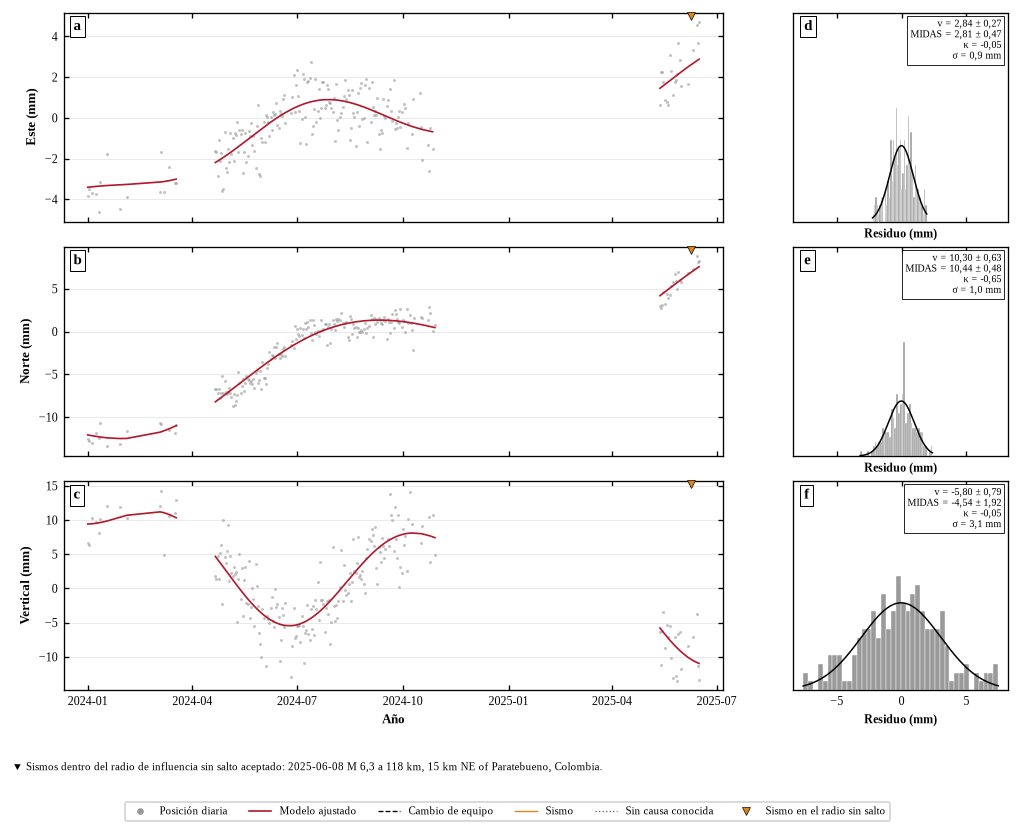

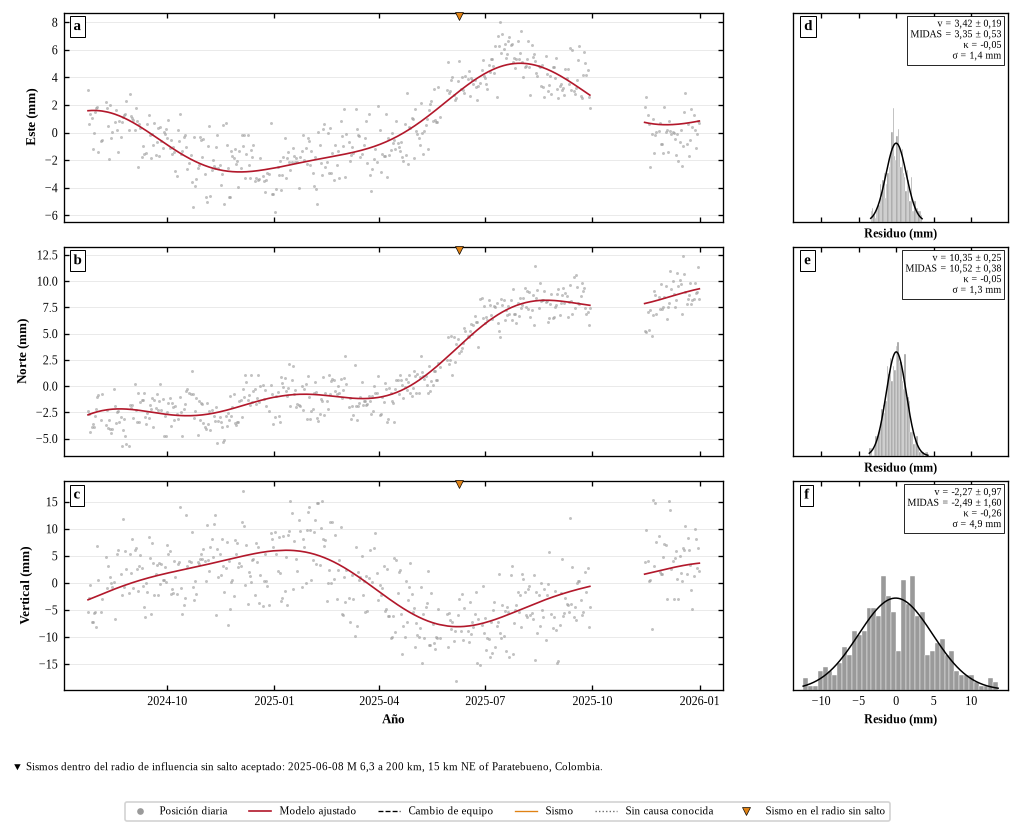

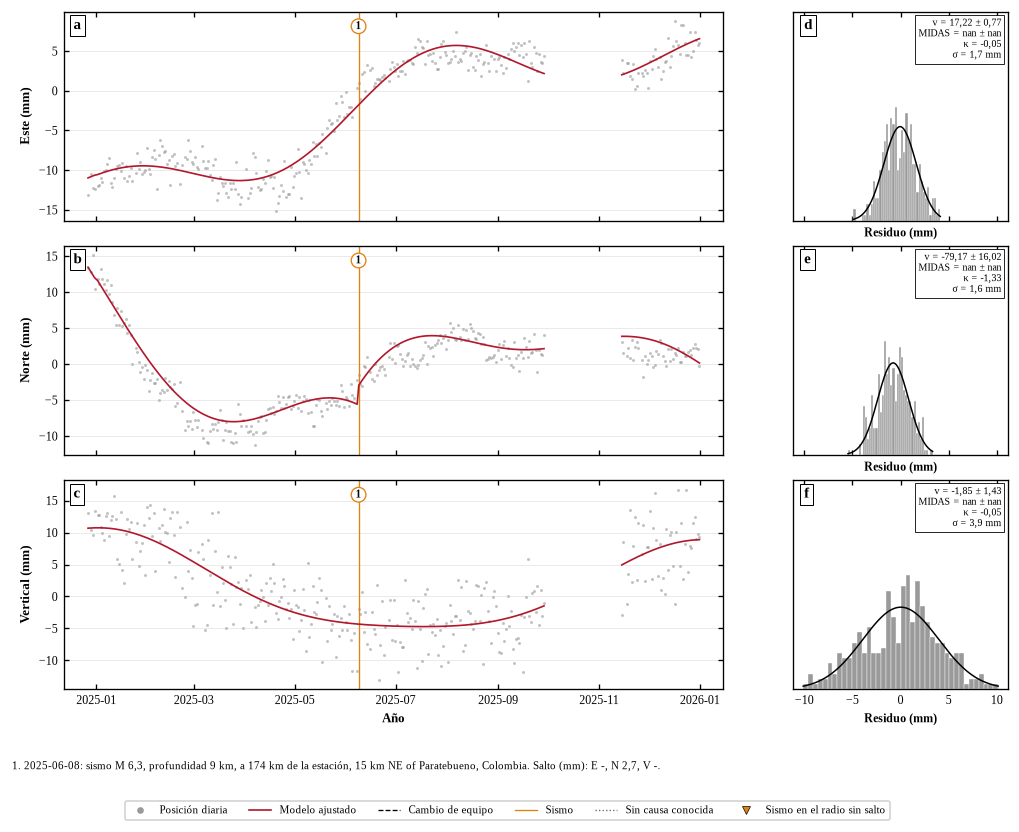

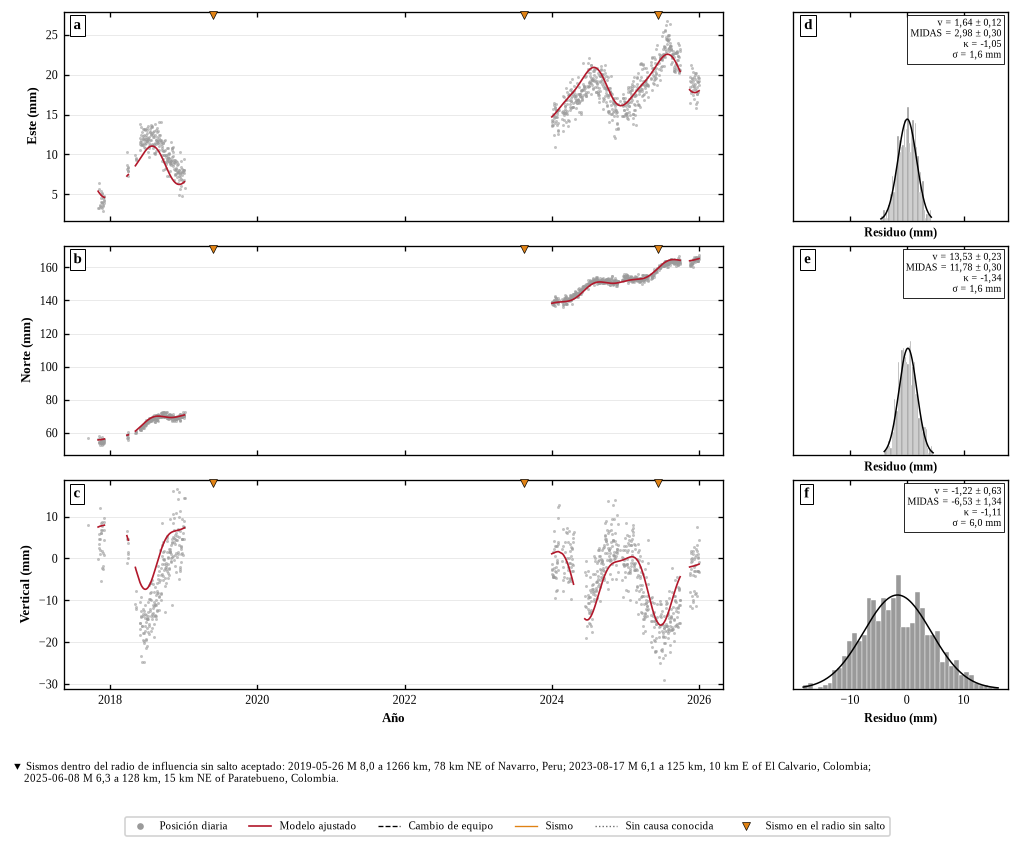

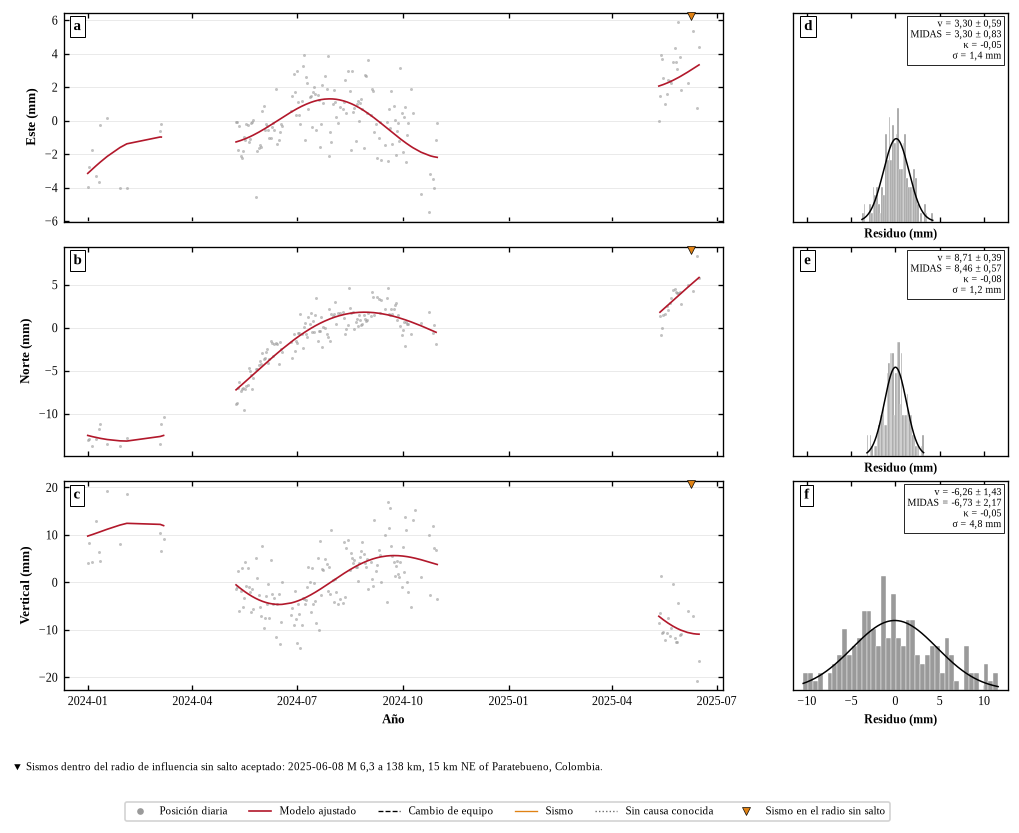

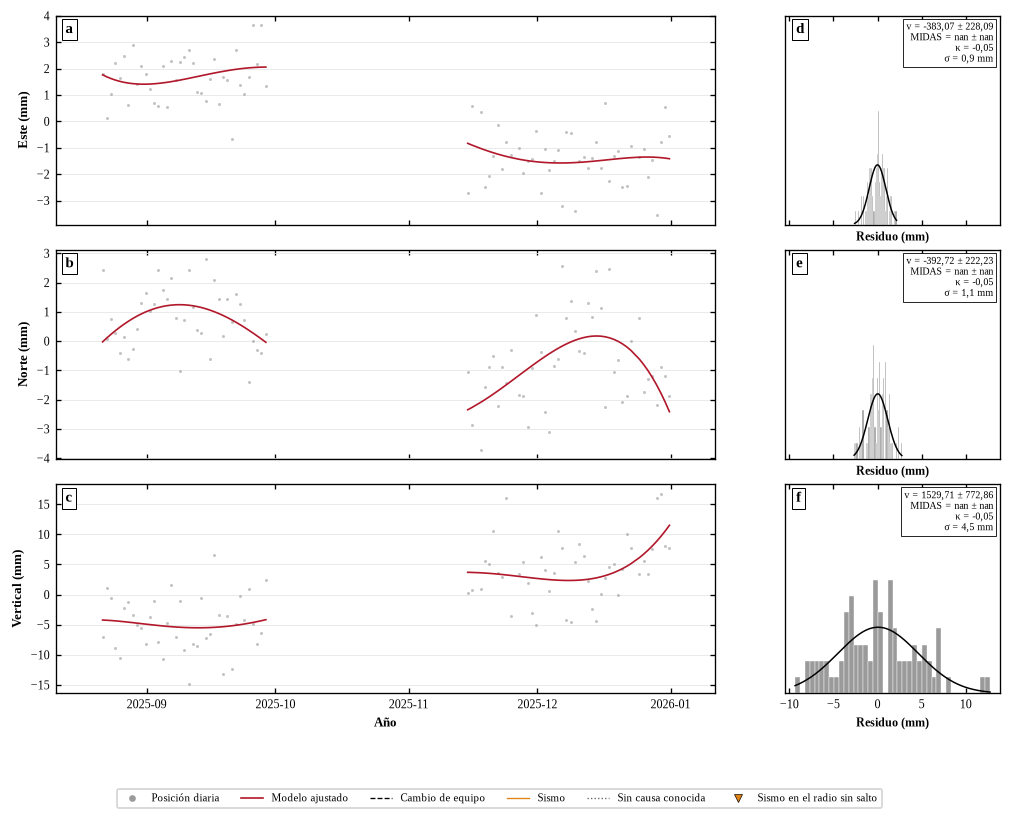

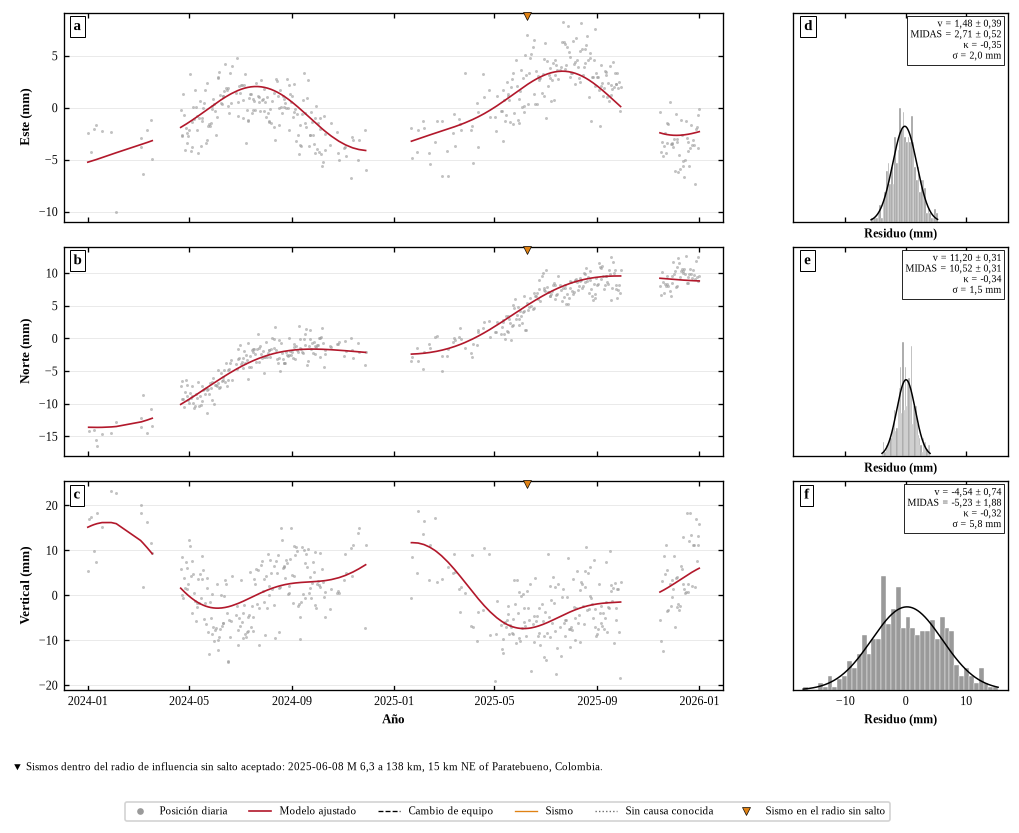

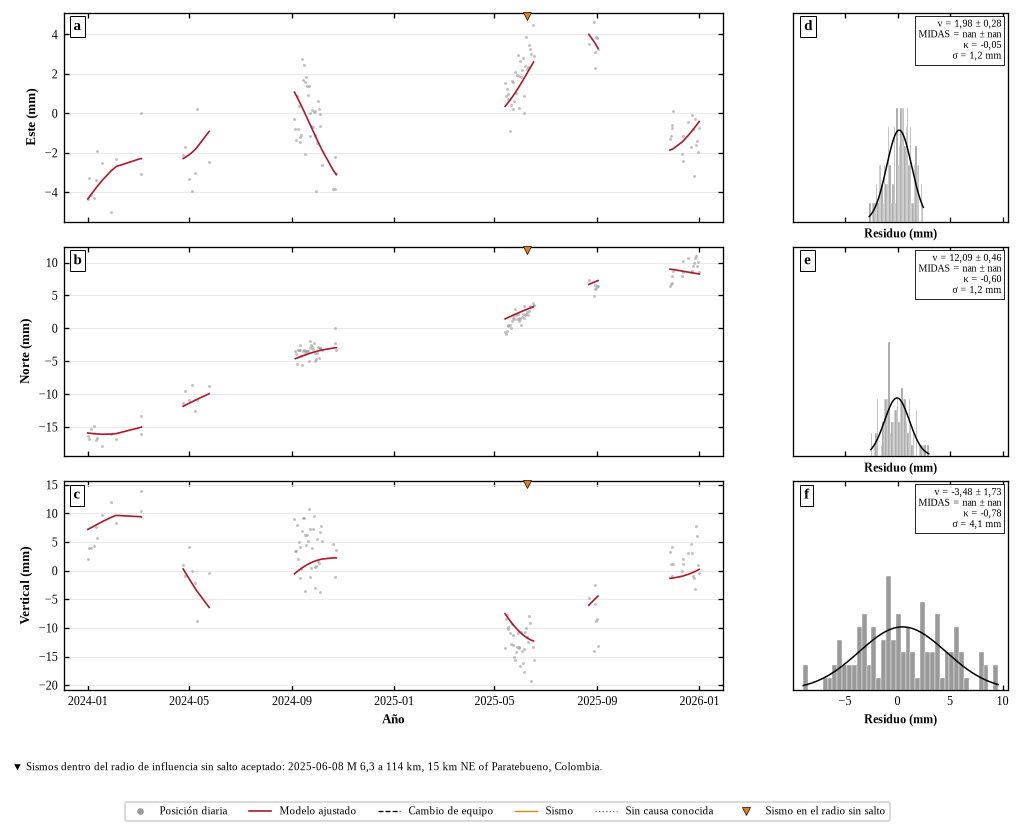

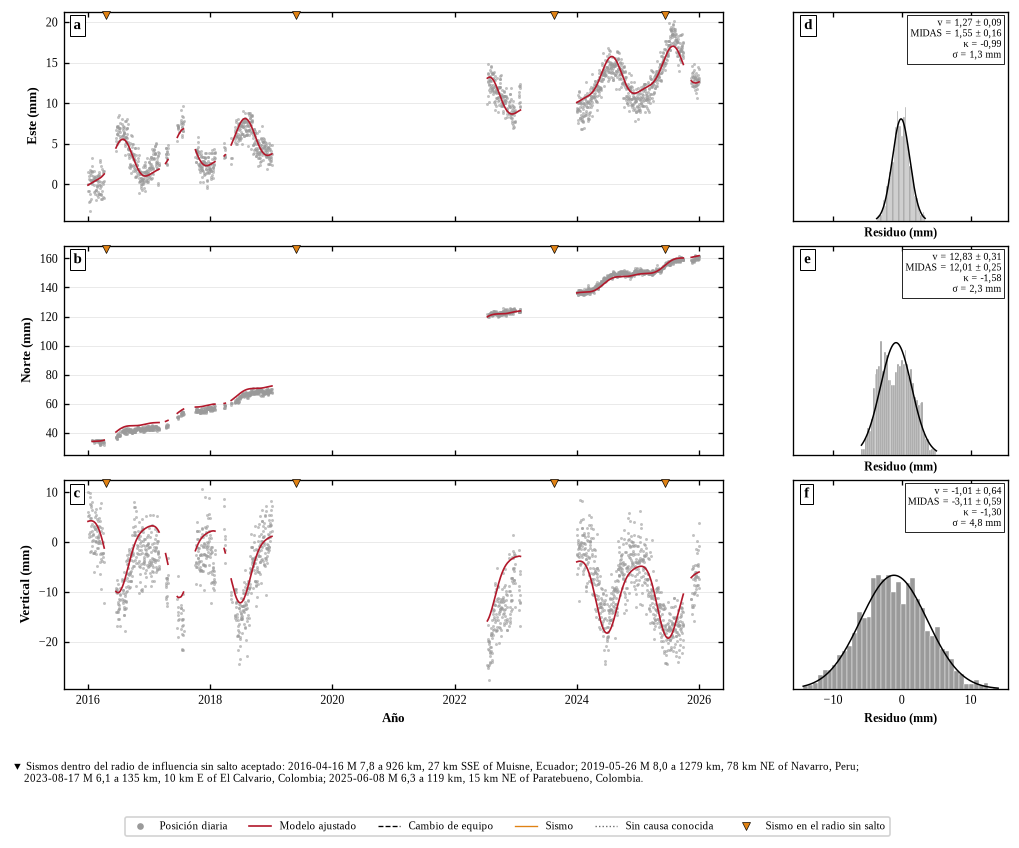

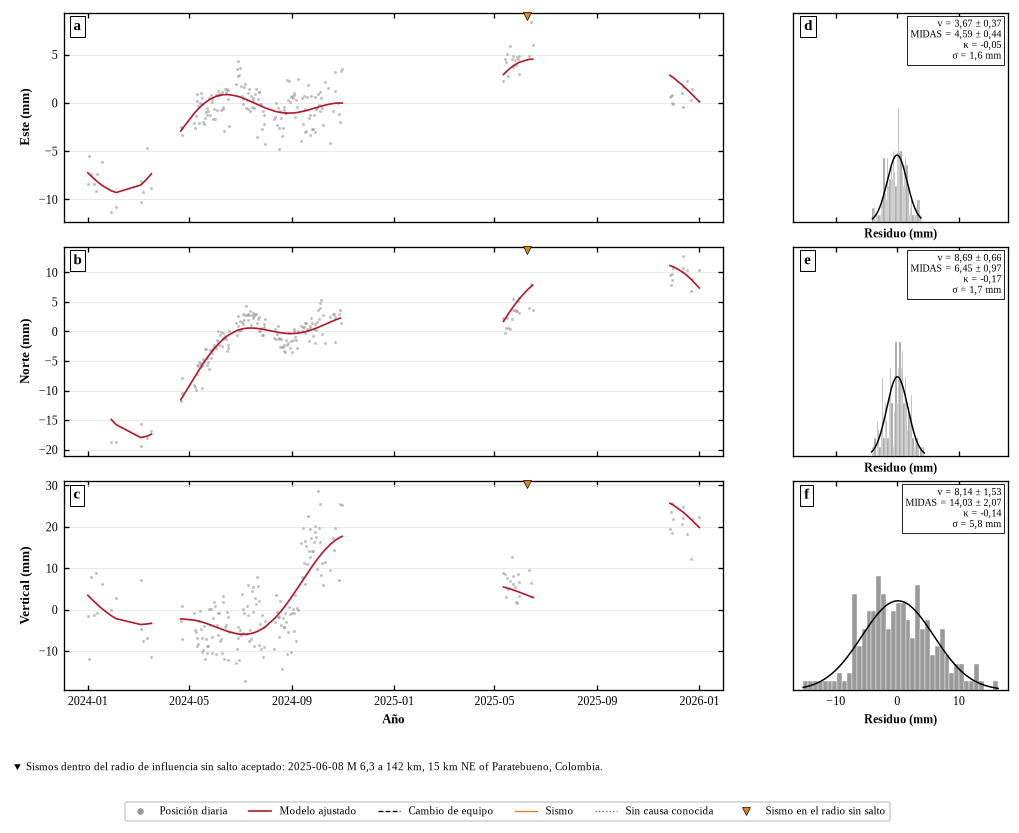

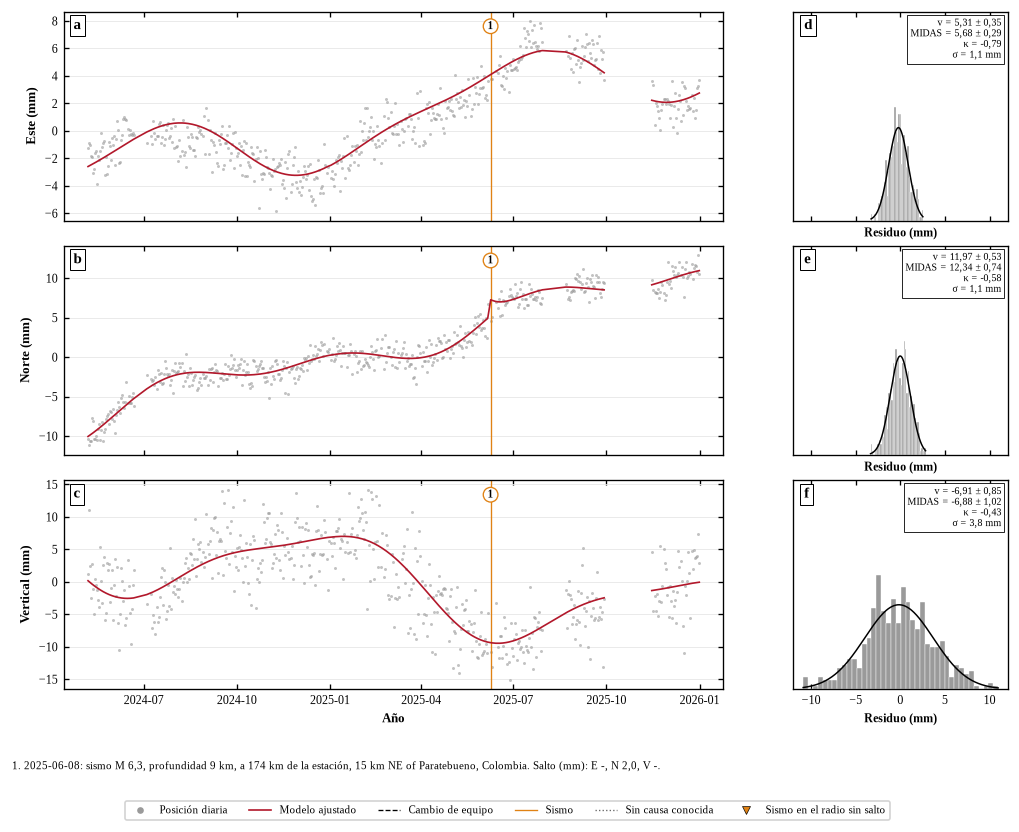

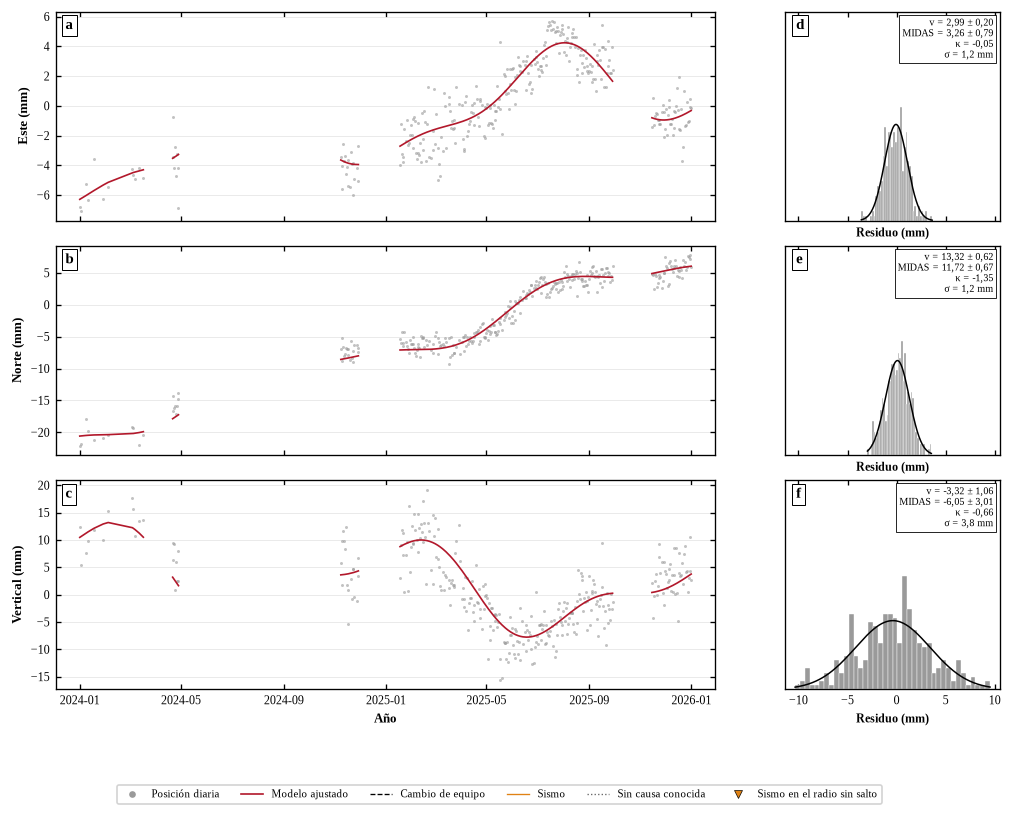

ok: 12 figuras


In [13]:
# Anio decimal a fecha
def a_fecha(t):
    t = np.asarray(t, dtype=float)
    base = pd.to_datetime(np.floor(t).astype(int).astype(str), format="%Y")
    return (base + pd.to_timedelta((t - np.floor(t)) * DIAS_ANIO, unit="D")).to_numpy().astype("datetime64[ns]")


# Inserta NaN donde hay huecos mayores que MAX_HUECO_DIAS para que la linea no cruce los vacios
def con_huecos(t, valores):
    corte = np.where(np.diff(t) * DIAS_ANIO > MAX_HUECO_DIAS)[0] + 1
    return np.insert(a_fecha(t), corte, np.datetime64("NaT", "ns")), np.insert(valores, corte, np.nan)


# Cambios de equipo, sismos de steps.txt y sismos del catalogo (con su distancia) de una estacion
def contexto_estacion(estacion, carpeta):
    lat, lon = SITIOS_GNSS[estacion]
    pasos = leer_saltos(carpeta / "steps.txt", estacion)
    catalogo = leer_sismos(carpeta / f"sismos_usgs_{estacion}.csv")
    catalogo = catalogo[(catalogo["mag"] >= MAG_MIN) & (catalogo["t"] >= INICIO_T)].copy()
    catalogo["dist"] = distancia_km(lat, lon, catalogo["lat"], catalogo["lon"])
    catalogo["hipo"] = np.sqrt(catalogo["dist"] ** 2 + catalogo["prof"].fillna(0) ** 2)
    return {"equipo": pasos.loc[pasos["tipo"].isin([1, 3]), "t"].to_numpy(),
            "pasos_sismo": pasos.loc[pasos["tipo"] == 2, "t"].to_numpy(), "catalogo": catalogo}


# Causa de un salto: texto corto, tipo (equipo, sismo o desconocida) y detalle del sismo para la lista
def causa_salto(epoca, contexto):
    tol = TOL_EPOCAS_DIAS / DIAS_ANIO
    catalogo = contexto["catalogo"]
    cerca = catalogo[(catalogo["t"] - epoca).abs() <= tol]
    if (np.abs(contexto["equipo"] - epoca) <= tol).any():
        return "Cambio de equipo", "equipo", "cambio de equipo registrado en steps.txt"
    if len(cerca):
        q = cerca.loc[cerca["mag"].idxmax()]
        detalle = (f"sismo M {coma(q['mag'])}, profundidad {coma(q['prof'], 0)} km, a {coma(q['dist'], 0)} km de la estación"
                   + (f", {q['lugar']}" if q["lugar"] else ""))
        return f"M {coma(q['mag'])}", "sismo", detalle
    if (np.abs(contexto["pasos_sismo"] - epoca) <= tol).any():
        return "Sismo (NGL)", "sismo", "sismo del archivo steps.txt (sin evento en el catálogo de USGS)"
    return "Sin causa conocida", "desconocida", "sin causa conocida: revisar a mano"


# Une en una lista las epocas de salto de las tres componentes
def epocas_de_saltos(resultados_estacion):
    todas = [x["t"] for clave in COMPONENTES for x in resultados_estacion[clave]["saltos_info"]]
    return unir_cercanas(todas) if todas else np.array([])


# Salto de una componente que corresponde a una epoca, o None
def salto_en_epoca(res, epoca):
    for x in res["saltos_info"]:
        if abs(x["t"] - epoca) <= TOL_EPOCAS_DIAS / DIAS_ANIO:
            return x
    return None


ESTILO_SALTO = {"equipo": ("black", "--"), "sismo": ("#e08214", "-"), "desconocida": ("0.4", ":")}


# Lista de saltos y sismos para el pie de la figura, con lineas ya cortadas al ancho de la figura
def pie_de_figura(epocas, contexto, resultados, sin_salto):
    lineas = []
    for n, epoca in enumerate(epocas, 1):
        _, _, detalle = causa_salto(epoca, contexto)
        amplitudes = []
        for clave, nombre in COMPONENTES.items():
            x = salto_en_epoca(resultados[clave], epoca)
            amplitudes.append(f"{nombre[0]} {coma(x['amp'], 1)}" if x else f"{nombre[0]} -")
        fecha = str(a_fecha([epoca])[0].astype("datetime64[D]"))
        lineas += textwrap.wrap(f"{n}. {fecha}: {detalle}. Salto (mm): " + ", ".join(amplitudes) + ".",
                                width=PIE_ANCHO, subsequent_indent="    ")
    if sin_salto:
        catalogo = contexto["catalogo"]
        partes = []
        for q in sorted(sin_salto)[:6]:
            fila = catalogo.loc[(catalogo["t"] - q).abs().idxmin()]
            lugar = f", {fila['lugar']}" if fila["lugar"] else ""
            partes.append(f"{str(a_fecha([q])[0].astype('datetime64[D]'))} M {coma(fila['mag'])} a {coma(fila['dist'], 0)} km{lugar}")
        resto = f" y {len(sin_salto) - 6} más" if len(sin_salto) > 6 else ""
        lineas += textwrap.wrap("▼ Sismos dentro del radio de influencia sin salto aceptado: " + "; ".join(partes) + resto + ".",
                                width=PIE_ANCHO, subsequent_indent="    ")
    return lineas


# Figura de una estacion: series con modelo, saltos numerados e histograma de residuos, con la lista de sismos abajo
def figura_estacion(estacion, resultados, contexto):
    epocas = epocas_de_saltos(resultados)
    catalogo = contexto["catalogo"]
    en_radio = catalogo[(catalogo["hipo"] <= radio_sismo(catalogo["mag"]))]
    sin_salto = [q for q in en_radio["t"] if not (len(epocas) and (np.abs(epocas - q) <= TOL_EPOCAS_DIAS / DIAS_ANIO).any())]
    # Solo se muestran los eventos dentro del periodo con datos, para que el eje se ajuste a la serie
    t_ini = min(res["t"].min() for res in resultados.values())
    t_fin = max(res["t"].max() for res in resultados.values())
    margen = max((t_fin - t_ini) * 0.04, 0.03)
    epocas = np.asarray([e for e in epocas if t_ini - margen <= e <= t_fin + margen])
    sin_salto = [q for q in sin_salto if t_ini - margen <= q <= t_fin + margen]
    pie = pie_de_figura(epocas, contexto, resultados, sin_salto)
    pie_in = 0.55 + 0.135 * len(pie)          # alto de la lista y la leyenda, en pulgadas
    alto = 6.2 + pie_in
    fig, ejes = plt.subplots(3, 2, figsize=(FIG_ANCHO_ESTACION, alto), sharex="col",
                             gridspec_kw={"width_ratios": [4, 1.3], "wspace": 0.16, "hspace": 0.12})
    for fila, (clave, nombre) in enumerate(COMPONENTES.items()):
        res = resultados[clave]
        fechas = a_fecha(res["t"])
        eje = ejes[fila, 0]
        eje.plot(fechas, res["y"], "o", ms=1.8, color=COLOR_DATOS, alpha=0.6, mew=0, zorder=1)
        eje.plot(*con_huecos(res["t"], res["y"] - res["resid"]), "-", lw=1.0, color=COLOR_ROJO, zorder=3)
        for n, epoca in enumerate(epocas, 1):
            _, tipo, _ = causa_salto(epoca, contexto)
            color, estilo = ESTILO_SALTO[tipo]
            x = a_fecha([epoca])[0]
            eje.axvline(x, color=color, lw=0.8, ls=estilo, zorder=2)
            eje.text(x, 0.93, str(n), transform=eje.get_xaxis_transform(), ha="center", va="center", fontsize=6.5,
                     fontweight="bold", zorder=6, bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=color, lw=0.8))
        if sin_salto:
            eje.plot(a_fecha(sin_salto), [0.985] * len(sin_salto), marker="v", ls="", ms=4.5, color="#e08214",
                     mec="black", mew=0.4, transform=eje.get_xaxis_transform(), clip_on=False, zorder=6)
        eje.set_ylabel(f"{nombre} (mm)", fontsize=8)
        eje.grid(axis="y", color="0.9", lw=0.5)
        eje.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=8))
        corto = res["t"].max() - res["t"].min() < 3
        eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m" if corto else "%Y"))
        letra_panel(eje, "abc"[fila], x=0.015)
        estilo_eje(eje)
        eje_h = ejes[fila, 1]
        residuo = res["resid"]
        sigma = residuo.std()
        eje_h.hist(residuo, bins=40, density=True, color=COLOR_DATOS, edgecolor="white", lw=0.25, zorder=1)
        x = np.linspace(residuo.min(), residuo.max(), 300)
        eje_h.plot(x, np.exp(-0.5 * ((x - residuo.mean()) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)), color="black", lw=0.9, zorder=3)
        eje_h.set_ylim(0, eje_h.get_ylim()[1] * 1.75)
        texto = (f"v = {coma(res['velocidad'], 2)} ± {coma(res['error'], 2)}\n"
                 f"MIDAS = {coma(res['midas'], 2)} ± {coma(res['error_midas'], 2)}\n"
                 f"κ = {coma(res['kappa'], 2)}\nσ = {coma(sigma, 1)} mm")
        eje_h.text(0.97, 0.97, texto, transform=eje_h.transAxes, va="top", ha="right", fontsize=6,
                   bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="black", lw=0.5), zorder=6)
        eje_h.set_yticks([])
        eje_h.set_xlabel("Residuo (mm)", fontsize=7)
        letra_panel(eje_h, "def"[fila], x=0.05)
        estilo_eje(eje_h)
    ejes[0, 0].set_xlim(a_fecha([t_ini - margen])[0], a_fecha([t_fin + margen])[0])
    ejes[-1, 0].set_xlabel("Año", fontsize=8)
    manijas = [Line2D([], [], color=COLOR_DATOS, marker="o", ls="", ms=3, label="Posición diaria"),
               Line2D([], [], color=COLOR_ROJO, lw=1.0, label="Modelo ajustado"),
               Line2D([], [], color="black", lw=0.8, ls="--", label="Cambio de equipo"),
               Line2D([], [], color="#e08214", lw=0.8, label="Sismo"),
               Line2D([], [], color="0.4", lw=0.8, ls=":", label="Sin causa conocida"),
               Line2D([], [], color="#e08214", marker="v", mec="black", mew=0.4, ls="", ms=4.5, label="Sismo en el radio sin salto")]
    fig.legend(handles=manijas, loc="lower center", ncol=6, fontsize=6.5, frameon=True, framealpha=0.85,
               edgecolor="0.8", bbox_to_anchor=(0.5, 0.0))
    if pie:
        fig.text(0.02, 0.4 / alto + 0.135 * len(pie) / alto, "\n".join(pie), ha="left", va="top", fontsize=6.5)
    fig.subplots_adjust(top=0.985, bottom=(pie_in + 0.45) / alto, left=0.07, right=0.985)
    titulo_figura(f"Serie de posición diaria de la estación {estacion}, modelo ajustado y residuos por componente")
    plt.show()
    plt.close(fig)


for estacion, resultado in resultados.items():
    figura_estacion(estacion, resultado, contexto_estacion(estacion, GNSS_DIR))
print(f"ok: {len(resultados)} figuras")

## 13. Tabla de velocidades

Presenta, en una sola tabla agrupada por estación, la velocidad de cada componente desde `INICIO_DATOS` con su incertidumbre, la velocidad MIDAS y el índice espectral κ. La columna `Interpretable` indica si el registro tiene al menos `MIN_ANIOS` años; los registros más cortos se muestran pero no deben usarse para interpretar movimientos, porque la velocidad de una serie corta se confunde con la señal estacional (Blewitt y Lavallée, 2002). La tabla completa se guarda en `velocidades_gnss.csv`, que es el insumo del notebook 3. El marco es IGS20 y las incertidumbres son de 1σ.

In [14]:
# Texto "valor ± incertidumbre" con coma decimal
def con_error(valor, error):
    if not np.isfinite(valor):
        return "-"
    return f"{valor:.2f} ± {error:.2f}".replace(".", ",") if np.isfinite(error) else f"{valor:.2f}".replace(".", ",")


if tabla.empty:
    print("sin resultados: procese al menos una estacion (seccion 11)")
else:
    tabla.to_csv(RESULTADOS_DIR / "velocidades_gnss.csv", index=False)
    presentable = tabla.copy()
    # Con menos de un año de registro no se puede separar la señal estacional de la tendencia: no se muestra la velocidad
    presentable["registro"] = [con_error(v, e) if a >= 1.0 else "-" for v, e, a in zip(presentable["velocidad"], presentable["error"], presentable["anios"])]
    presentable["midas_txt"] = [con_error(v, e) for v, e in zip(presentable["midas"], presentable["error_midas"])]
    presentable["interpretable_txt"] = np.where(presentable["interpretable"], "Sí", "No")
    tabla_apa(presentable[["estacion", "componente", "anios", "dias", "cobertura", "registro", "midas_txt", "kappa", "saltos", "interpretable_txt"]].rename(columns={
        "estacion": "Estación", "componente": "Componente", "anios": "Años", "dias": "Días", "cobertura": "Cobertura (%)", "registro": "Velocidad (mm/año)",
        "midas_txt": "MIDAS (mm/año)", "kappa": "κ", "saltos": "Saltos", "interpretable_txt": "Interpretable"}),
        "Velocidades GNSS por estación y componente",
        agrupar="Estación")
    print(f"ok: {int(tabla['interpretable'].sum() // 3)} estaciones interpretables de {tabla['estacion'].nunique()} | tabla en {RESULTADOS_DIR / 'velocidades_gnss.csv'}")


ok: 2 estaciones interpretables de 12 | tabla en /home/jovyan/Tesis_InSAR_Rio_Suarez/03_resultados/gnss/velocidades_gnss.csv


## 14. Velocidades horizontales y verticales en la cuenca

Las velocidades horizontales se refieren a la placa Suramericana restando el movimiento que predice su polo de Euler en el modelo ITRF2020-PMM (Altamimi et al., 2023). La velocidad del modelo en cada estación es el producto vectorial entre el vector de rotación y la posición de la estación, proyectado a este y norte. Las coordenadas son las de `SITIOS_GNSS` (sección 3).

El mapa dibuja el contorno de la cuenca (`ARCHIVO_AREA`), las velocidades horizontales como flechas y la velocidad vertical como el color del círculo de cada estación (rojo asciende, azul desciende). Los límites del mapa se ajustan para que las flechas queden completas. Solo las estaciones con al menos `MIN_ANIOS` años llevan flecha y color; las de registro más corto se marcan con un círculo blanco, porque su velocidad no es confiable y una flecha larga sin sustento engaña la lectura. Las etiquetas se reubican solas para no taparse.

Antes de calcular respecto a la placa se debe completar `POLO_PLACA`. Los parámetros del polo se pueden copiar de SARI (opción *Select a plate model*, modelo ITRF2020, y enlace *Show the selected plate model*) o de la tabla del modelo en Altamimi et al. (2023). Mientras `POLO_PLACA` sea `None`, el mapa muestra las velocidades en el marco IGS20 y la celda lo indica.

Estación,Componente,Placa (mm/año),Relativa (mm/año)
FQNE,Este,"-5,41","7,05"
FQNE,Norte,"10,19","3,34"
TUNA,Este,"-5,41","6,68"
TUNA,Norte,"10,23","2,60"


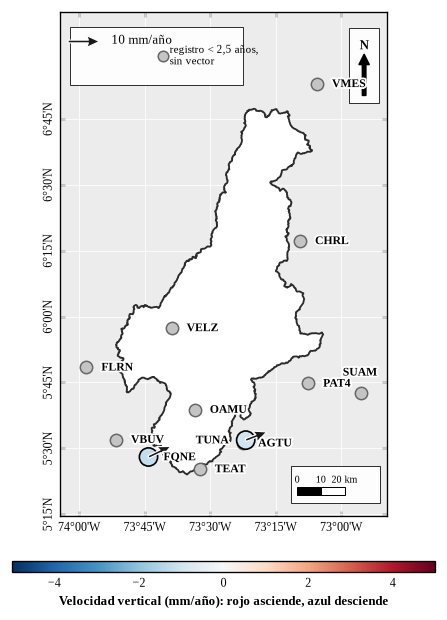

ok: mapa de velocidades guardado


In [15]:
# Velocidad horizontal respecto a una placa con un polo de Euler en grados y grados por millon de anios
def velocidad_placa(lat, lon, polo):
    a, f = 6378137.0, 1 / 298.257223563
    fi, la = np.radians(lat), np.radians(lon)
    N = a / np.sqrt(1 - f * (2 - f) * np.sin(fi) ** 2)
    r = N * np.array([np.cos(fi) * np.cos(la), np.cos(fi) * np.sin(la), (1 - f) ** 2 * np.sin(fi)])
    pf, pl = np.radians(polo[0]), np.radians(polo[1])
    omega = np.radians(polo[2]) * 1e-6 * np.array(
        [np.cos(pf) * np.cos(pl), np.cos(pf) * np.sin(pl), np.sin(pf)])
    v = np.cross(omega, r) * 1000
    este = np.array([-np.sin(la), np.cos(la), 0])
    norte = np.array([-np.sin(fi) * np.cos(la), -np.sin(fi) * np.sin(la), np.cos(fi)])
    return v @ este, v @ norte


# Contorno de la cuenca en WGS 84, o None si no se puede leer
def leer_cuenca():
    if gpd is None or not ARCHIVO_AREA.exists():
        return None
    return gpd.read_file(ARCHIVO_AREA).to_crs(4326)


CUENCA = leer_cuenca()
if CUENCA is None:
    print(f"aviso: sin contorno de la cuenca ({ARCHIVO_AREA.name}); los mapas salen sin ella")


# Limites del mapa que incluyen estaciones, puntas de flechas y cuenca, con margen
def limites_mapa(lons, lats, extra_x=(), extra_y=(), margen=0.08):
    xs = list(lons) + list(extra_x)
    ys = list(lats) + list(extra_y)
    if CUENCA is not None:
        x0, y0, x1, y1 = CUENCA.total_bounds
        xs += [x0, x1]
        ys += [y0, y1]
    return min(xs) - margen, max(xs) + margen, min(ys) - margen - 0.06, max(ys) + margen


# Marco comun de los mapas: fondo, cuenca, cuadricula, coordenadas en grados y minutos, norte y titulo
def decorar_mapa(eje, limites, titulo, letra):
    eje.set_facecolor(FONDO)
    eje.set_xlim(limites[0], limites[1])
    eje.set_ylim(limites[2], limites[3])
    eje.set_aspect(1 / np.cos(np.radians((limites[2] + limites[3]) / 2)))
    paso = 0.25
    xs = np.arange(np.ceil(limites[0] / paso) * paso, limites[1], paso)
    ys = np.arange(np.ceil(limites[2] / paso) * paso, limites[3], paso)
    for x in xs:
        eje.axvline(x, color="white", lw=0.6, alpha=0.8, zorder=1)
    for y in ys:
        eje.axhline(y, color="white", lw=0.6, alpha=0.8, zorder=1)
    if CUENCA is not None:
        CUENCA.plot(ax=eje, facecolor="white", edgecolor="#2b2b2b", lw=1.1, zorder=2, alpha=1)
        eje.set_xlabel("")
        eje.set_ylabel("")
    eje.set_xlim(limites[0], limites[1])
    tope = limites[3] + 0.10 * (limites[3] - limites[2])  # margen superior para la rosa del norte
    eje.set_ylim(limites[2], tope)
    eje.set_xticks(xs)
    eje.set_xticklabels([gms(v, "E", "W") for v in xs])
    eje.set_yticks(ys)
    eje.set_yticklabels([gms(v, "N", "S") for v in ys], rotation=90, va="center")
    ancho, alto = limites[1] - limites[0], tope - limites[2]
    nx, ny = limites[1] - 0.07 * ancho, tope - 0.17 * alto
    eje.add_patch(plt.Rectangle((nx - 0.045 * ancho, ny - 0.012 * alto), 0.09 * ancho, 0.15 * alto,
                                facecolor="white", edgecolor="black", lw=0.5, alpha=0.95, zorder=8))
    eje.annotate("", xy=(nx, ny + 0.085 * alto), xytext=(nx, ny + 0.004 * alto), zorder=9,
                 arrowprops=dict(facecolor="black", edgecolor="black", width=2, headwidth=6, headlength=6))
    eje.text(nx, ny + 0.09 * alto, "N", ha="center", va="bottom", fontsize=7.5, fontweight="bold", zorder=9)
    if titulo:
        eje.set_title(titulo)
    estilo_eje(eje)


# Coloca cada etiqueta en la posicion (de ocho) que menos se cruza con otras etiquetas y con los circulos
def colocar_etiquetas(fig, eje, xs, ys, nombres, fuente=7):
    fig.canvas.draw()
    eje.apply_aspect()
    px = eje.transData.transform(np.column_stack([xs, ys]))
    f = fig.dpi / 72
    candidatos = [(9, 0, "left", "center"), (-9, 0, "right", "center"), (0, 9, "center", "bottom"), (0, -9, "center", "top"),
                  (8, 8, "left", "bottom"), (-8, 8, "right", "bottom"), (8, -8, "left", "top"), (-8, -8, "right", "top")]
    cajas, caja_eje = [], eje.get_window_extent()
    orden = np.argsort([-np.sum(np.hypot(*(px - p).T) < 60 * f) for p in px])
    for i in orden:
        w, h = (0.62 * fuente * len(nombres[i]) + 3) * f, (fuente + 3) * f
        mejor = None
        for dx, dy, ha, va in candidatos:
            cx, cy = px[i, 0] + dx * f, px[i, 1] + dy * f
            x0 = cx if ha == "left" else cx - w if ha == "right" else cx - w / 2
            y0 = cy if va == "bottom" else cy - h if va == "top" else cy - h / 2
            caja = (x0, y0, x0 + w, y0 + h)
            costo = 0.0
            for otra in cajas:
                ox = max(0, min(caja[2], otra[2]) - max(caja[0], otra[0]))
                oy = max(0, min(caja[3], otra[3]) - max(caja[1], otra[1]))
                costo += ox * oy
            for q in px:
                if caja[0] - 7 * f < q[0] < caja[2] + 7 * f and caja[1] - 7 * f < q[1] < caja[3] + 7 * f:
                    costo += 60 * f * f
            if caja[0] < caja_eje.x0 or caja[2] > caja_eje.x1 or caja[1] < caja_eje.y0 or caja[3] > caja_eje.y1:
                costo += 1e6
            if mejor is None or costo < mejor[0]:
                mejor = (costo, dx, dy, ha, va, caja)
        _, dx, dy, ha, va, caja = mejor
        cajas.append(caja)
        eje.annotate(nombres[i], (xs[i], ys[i]), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=fuente,
                     fontweight="bold", zorder=10, path_effects=[pe.withStroke(linewidth=2.2, foreground="white")])


# Mapa de vectores horizontales (flechas) y velocidad vertical (color del circulo) de las estaciones interpretables
def mapa_vectores(tabla_v, columna_h, rotulo, nombre):
    puntos = []
    for estacion in dict.fromkeys(tabla_v["estacion"]):
        fila = tabla_v[tabla_v["estacion"] == estacion].set_index("componente")
        if {"Este", "Norte"} <= set(fila.index) and estacion in SITIOS_GNSS:
            lat, lon = SITIOS_GNSS[estacion]
            vertical = fila.loc["Vertical", "velocidad"] if "Vertical" in fila.index else np.nan
            puntos.append((estacion, lon, lat, fila.loc["Este", columna_h], fila.loc["Norte", columna_h],
                           vertical, bool(fila.loc["Este", "interpretable"])))
    nombres, lons, lats, ve, vn, vv, interp = (np.array(x) for x in zip(*puntos))
    interp = interp.astype(bool)
    escala = 10 / 0.12                     # mm/anio por grado de flecha
    limites = limites_mapa(lons, lats, lons[interp] + ve[interp] / escala, lats[interp] + vn[interp] / escala, margen=0.1)
    fig, eje = plt.subplots(figsize=(FIG_ANCHO, 7.0))
    decorar_mapa(eje, limites, "", "a")
    lim_v = max(5, np.nanmax(np.abs(vv[interp]))) if interp.any() else 5
    if (~interp).any():
        eje.scatter(lons[~interp], lats[~interp], s=55, facecolor="#c4c4c4", edgecolor="0.4", lw=0.9, zorder=5)
    puntos_v = None
    if interp.any():
        puntos_v = eje.scatter(lons[interp], lats[interp], c=vv[interp], cmap="RdBu_r", vmin=-lim_v, vmax=lim_v, s=120,
                               edgecolor="black", lw=1.0, zorder=6)
        q = eje.quiver(lons[interp], lats[interp], ve[interp], vn[interp], angles="xy", scale_units="xy", scale=escala,
                       width=0.0085, color="#1a1a1a", edgecolor="white", linewidth=0.7, headwidth=4.2, headlength=4.6,
                       headaxislength=4.0, zorder=7)
    colocar_etiquetas(fig, eje, lons, lats, nombres)
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    caja_x, caja_y = x0 + 0.03 * (x1 - x0), y1 - 0.145 * (y1 - y0)
    eje.add_patch(plt.Rectangle((caja_x, caja_y), 0.53 * (x1 - x0), 0.115 * (y1 - y0), facecolor="white", edgecolor="black",
                                lw=0.5, alpha=0.95, zorder=8))
    if interp.any():
        clave = eje.quiverkey(q, 0.12, 0.9425, 10, "10 mm/año", labelpos="E", coordinates="axes", fontproperties={"size": 7.5})
        clave.set_zorder(10)
    eje.scatter([caja_x + 0.285 * (x1 - x0)], [caja_y + 0.0575 * (y1 - y0)], s=40, facecolor="#c4c4c4", edgecolor="0.4", lw=0.9, zorder=9)
    eje.text(caja_x + 0.305 * (x1 - x0), caja_y + 0.0575 * (y1 - y0), f"registro < {MIN_ANIOS} años,\nsin vector".replace(".", ",", 1),
             va="center", fontsize=6.5, zorder=9)
    km = 20 / (111.32 * np.cos(np.radians((y0 + y1) / 2)))
    bx, by = x1 - 0.13 * (x1 - x0) - km, y0 + 0.05 * (y1 - y0)
    eje.add_patch(plt.Rectangle((bx - 0.02 * (x1 - x0), by - 0.025 * (y1 - y0)), km + 0.13 * (x1 - x0), 0.075 * (y1 - y0),
                                facecolor="white", edgecolor="black", lw=0.5, alpha=0.95, zorder=8))
    for k in range(2):
        eje.add_patch(plt.Rectangle((bx + k * km / 2, by - 0.008 * (y1 - y0)), km / 2, 0.016 * (y1 - y0),
                                    facecolor="black" if k == 0 else "white", edgecolor="black", lw=0.6, zorder=9))
    for v, x, ha in ((0, bx, "center"), (10, bx + km / 2, "center"), ("20 km", bx + km, "center")):
        eje.text(x, by + 0.012 * (y1 - y0), str(v), ha=ha, va="bottom", fontsize=6, zorder=9)
    if puntos_v is not None:
        barra = fig.colorbar(puntos_v, ax=eje, orientation="horizontal", shrink=0.7, pad=0.07, aspect=40)
        barra.set_label("Velocidad vertical (mm/año): rojo asciende, azul desciende", fontsize=8)
        barra.ax.tick_params(labelsize=7)
    titulo_figura(rotulo)
    plt.show()
    plt.close(fig)


# Latitud, longitud (grados) y tasa (grados por millon de anios) del polo de la placa Suramericana
# Polo de Euler de la placa Suramericana en ITRF2020-PMM (Altamimi et al., 2023): latitud, longitud (grados) y velocidad angular (grados por millon de anios)
POLO_PLACA = (-22.225, -132.785, 0.1153)

if tabla.empty:
    print("sin resultados: procese al menos una estacion (seccion 11)")
else:
    if POLO_PLACA is None:
        tabla["v_marco"] = tabla["velocidad"]
        mapa_vectores(tabla, "v_marco", "Velocidades GNSS horizontales y verticales en la cuenca, marco IGS20", "figura_vectores_gnss_igs20")
        print("pendiente: complete POLO_PLACA con el polo de ITRF2020-PMM (SARI o Altamimi et al., 2023) y vuelva a correr esta celda")
    else:
        modelo = []
        for _, fila in tabla.iterrows():
            lat, lon = SITIOS_GNSS[fila["estacion"]]
            v_este, v_norte = velocidad_placa(lat, lon, POLO_PLACA)
            modelo.append(v_este if fila["componente"] == "Este" else v_norte if fila["componente"] == "Norte" else 0.0)
        tabla["v_placa"] = modelo
        tabla["v_relativa"] = tabla["velocidad"] - tabla["v_placa"]
        interpretables = tabla[tabla["interpretable"]]  # la tabla y el CSV solo llevan estaciones con registro suficiente
        interpretables[interpretables["componente"].isin(["Este", "Norte"])].to_csv(RESULTADOS_DIR / "velocidades_gnss_placa.csv", index=False)
        tabla_apa(interpretables[interpretables["componente"].isin(["Este", "Norte"])][["estacion", "componente", "v_placa", "v_relativa"]].rename(columns={
            "estacion": "Estación", "componente": "Componente", "v_placa": "Placa (mm/año)", "v_relativa": "Relativa (mm/año)"}),
            "Velocidad horizontal respecto a la placa Suramericana")
        mapa_vectores(tabla, "v_relativa", "Velocidades GNSS horizontales respecto a la placa Suramericana y verticales en la cuenca", "figura_vectores_gnss_placa")
    print("ok: mapa de velocidades guardado")

## Referencias

Altamimi, Z., Métivier, L., Rebischung, P., Collilieux, X., Chanard, K. y Barnoud, J. (2023). ITRF2020 plate motion model. *Geophysical Research Letters, 50*(18), e2023GL106373. https://doi.org/10.1029/2023GL106373

Bevis, M. y Brown, A. (2014). Trajectory models and reference frames for crustal motion geodesy. *Journal of Geodesy, 88*(3), 283-311. https://doi.org/10.1007/s00190-013-0685-5

Blewitt, G., Hammond, W. C. y Kreemer, C. (2018). Harnessing the GPS data explosion for interdisciplinary science. *Eos, 99*. https://doi.org/10.1029/2018EO104623

Blewitt, G., Kreemer, C., Hammond, W. C. y Gazeaux, J. (2016). MIDAS robust trend estimator for accurate GPS station velocities without step detection. *Journal of Geophysical Research: Solid Earth, 121*(3), 2054-2068. https://doi.org/10.1002/2015JB012552

Blewitt, G. y Lavallée, D. (2002). Effect of annual signals on geodetic velocity. *Journal of Geophysical Research: Solid Earth, 107*(B7), ETG 9-1-ETG 9-11. https://doi.org/10.1029/2001JB000570

Bos, M. S., Fernandes, R. M. S., Williams, S. D. P. y Bastos, L. (2013). Fast error analysis of continuous GNSS observations with missing data. *Journal of Geodesy, 87*(4), 351-360. https://doi.org/10.1007/s00190-012-0605-0

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., ... Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357-362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Kass, R. E. y Raftery, A. E. (1995). Bayes factors. *Journal of the American Statistical Association, 90*(430), 773-795. https://doi.org/10.1080/01621459.1995.10476572

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61. https://doi.org/10.25080/Majora-92bf1922-00a

Python Software Foundation. (2024). *Python language reference* [Documentación]. https://www.python.org/

Santamaría-Gómez, A. (2019). SARI: Interactive GNSS position time series analysis software. *GPS Solutions, 23*(2), 52. https://doi.org/10.1007/s10291-019-0846-y

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461-464. https://doi.org/10.1214/aos/1176344136

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., ... SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261-272. https://doi.org/10.1038/s41592-019-0686-2

Williams, S. D. P. (2003). The effect of coloured noise on the uncertainties of rates estimated from geodetic time series. *Journal of Geodesy, 76*(9-10), 483-494. https://doi.org/10.1007/s00190-002-0283-4